# Capstone — mirrors your deployed research paper

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

**Lane 2, Refresh / Content Opportunity Scoring.** This notebook backs my research paper, section by section:
**https://nishankchandoliya.github.io/flyrank-ml-internship/** (the page itself lives in `docs/index.html`).

The question has not changed since W01: **which pages should a content reviewer look at first each month?** W03 to W07 built the answer step by step: a data contract, a frozen rule, a model, an honest validation and an action playbook. This notebook does two things:

1. **It collects the numbers the paper uses.** Every number comes from the committed receipts of W04 to W07 (`work/outputs/*.json`) or from a cell below. Before the new test, the code re-runs the W07 pipeline on the two earlier decision days and checks that it gives back the W06 and W07 numbers exactly.
2. **It runs the one test that was kept sealed since W03: June 2026.** The playbook is built on **31 May** from May data only (normal level from April, model trained on April→May labels). The expected results are written down in section 4 **before** June is read. Then June is read once, as hindsight, to check them.

**Short version:**
- **All eight expectations held on the sealed month.** On 31 May the model's precision@50 was 0.944, the frozen rule's 0.936 and the slide sort's 0.920, against a base rate of 0.637. The playbook's first 50 rows held 695 clicks a day that were still lost in June, against 38 for the model alone.
- **The model is level with the simple methods, not ahead of them**, on all three decision days. Its value is as one part of the order. Even there a plain clicks-at-stake order found as much or more lasting click loss in two of three months.
- **The queue finds losses that already happened and stayed.** On a label that only counts a fall after the decision day it scores at the base rate. Nothing here measures what a refresh does.
- **June had a portfolio-wide drop** (about 15% fewer impressions a day than May, while clicks rose). It raises June's base rate, so the results are also read as lift over the base rate.

**How to run it:** same as W03 to W07. In Colab save your Hugging Face READ token as a Secret named `HF_TOKEN`. Outside Colab the notebook reads the `HF_TOKEN` environment variable or asks for it with `getpass`. The token is never printed and never written into the notebook. Run it from a clone of the repo, because it reads the committed receipts in `work/outputs/` and writes the paper figures to `docs/figures/`. It reads the February to June partitions of the daily table (a few minutes). There is no random step: the models are logistic regressions and every tie is broken by `content_hash_id`, so a rerun gives the same tables.

In [1]:
%pip install -q duckdb huggingface_hub pandas scikit-learn matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import re
import json
import shutil
import getpass
import platform
from datetime import date
from pathlib import Path

import duckdb
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# The repo is public, so the token comes from a Colab Secret or an environment variable.
# It is never printed. getpass is only the last fallback.
HF_TOKEN = None
try:
    from google.colab import userdata
    HF_TOKEN = userdata.get("HF_TOKEN")
except Exception:
    pass
HF_TOKEN = HF_TOKEN or os.environ.get("HF_TOKEN") or getpass.getpass("Hugging Face READ token: ")

con = duckdb.connect()
con.execute(f"CREATE OR REPLACE SECRET hf (TYPE huggingface, TOKEN '{HF_TOKEN}')")
con.execute("SET enable_progress_bar = false")     # keeps the saved outputs clean
print("DuckDB connected. Hugging Face token loaded (not printed).")
VERSIONS = {"python": platform.python_version(), "scikit-learn": sklearn.__version__, "pandas": pd.__version__,
            "numpy": np.__version__, "duckdb": duckdb.__version__, "matplotlib": matplotlib.__version__}
print("Versions:", " | ".join(f"{k} {v}" for k, v in VERSIONS.items()))

# Works from work/notebooks/ (a local clone) and from the repo root (Colab after cloning the repo)
ROOT = Path("../..") if Path.cwd().name == "notebooks" else Path(".")
OUT_DIR, FIG_DIR, DOCS_DIR = ROOT / "work" / "outputs", ROOT / "work" / "figures", ROOT / "docs"
PAPER_FIG_DIR = DOCS_DIR / "figures"           # the deployed paper reads its images from here
for folder in (OUT_DIR, FIG_DIR, PAPER_FIG_DIR):
    folder.mkdir(parents=True, exist_ok=True)
PAPER_URL = "https://nishankchandoliya.github.io/flyrank-ml-internship/"
REPO_URL = "https://github.com/nishankchandoliya/flyrank-ml-internship"

DuckDB connected. Hugging Face token loaded (not printed).
Versions: python 3.13.17 | scikit-learn 1.9.1 | pandas 3.0.5 | numpy 2.5.3 | duckdb 2.0.0 | matplotlib 3.11.2


## 1. Question

*The research question and the decision it supports.*

**The question.** Which pages should a content reviewer look at first each month?

A FlyRank reviewer has time for about **50 pages a month** across many client sites. Some pages are losing search visibility and visits. Some only look like they are, because an earlier spike is ending or a new page is still settling in. A wrong pick costs about 20 minutes of review (a false alarm) or leaves a real loss unreviewed for another month (a miss). So the work judges the **top of a ranked list**, not accuracy over every page.

| | |
|---|---|
| **Decision** | which pages a person reviews first and which check to start with |
| **Who acts** | a content reviewer or SEO lead, once a month |
| **Unit** | one page in one month (`content_hash_id`), scored on the last day of the month |
| **Output** | a ranked queue: action, reason code, context codes and an order score |
| **Label (a proxy)** | `declined_next_month`: next month's impressions per day more than 20% below this month (W03) |
| **Main metric** | precision@50 next to the base rate (W02), plus the clicks a day still lost next month in the first 50 rows (W07) |

**Why data and ML help at all.** Several signals have to be read together and the obvious ones mislead: W04 found that sorting by volume does worse than random and that a short surge ending looks exactly like a decline. The cell below reads the receipts of W04 to W07 and prints the path the answer took.

In [3]:
def receipt(name):
    path = OUT_DIR / name
    assert path.exists(), f"{path} is missing: run this notebook from a clone of the repo (the receipts are committed)"
    return json.loads(path.read_text())


w04, audit, w05, w06, w07 = (receipt(n) for n in ["w04_baseline_metrics.json", "w04_signal_audit_verdicts.json",
                                                  "w05_model_metrics.json", "w06_validation_audit_metrics.json",
                                                  "w07_action_playbook_metrics.json"])
MAR, APR = ["mar_apr_test", "mean_over_folds"], ["apr_may_test", "mean_over_folds"]


def get(data, *keys):
    for key in keys:
        data = data[key]
    return data


STORY = pd.DataFrame([
    ("W03", "label base rate, March→April frame", get(w04, "data", "base_rate")),
    ("W04", "frozen rule P@50, all pages (random order)", f"{get(w04, 'all_pages', 'my rule: sliding_with_demand', 'P@50'):.3f} ({get(w04, 'all_pages', 'random order (DummyClassifier floor)', 'P@50'):.3f})"),
    ("W04", "volume-first P@50 (the quick-win habit)", get(w04, "all_pages", "volume only (quick-win style)", "P@50")),
    ("W04 audit", "late-month slide / CTR low for position / volume", " / ".join([get(audit, "verdicts", "#1 late-month slide", "verdict"),
                  get(audit, "verdicts", "flag: CTR low for its position (CTR-fix)", "verdict"), get(w04, "signal_verdicts", "A_volume_quick_win")])),
    ("W05", "model P@50 vs rule, client folds (trained on April outcomes)", f"{get(w05, 'mean_over_folds', 'logistic regression', 'P@50'):.3f} vs {get(w05, 'mean_over_folds', 'W04 rule (baseline)', 'P@50'):.3f}"),
    ("W06", "model P@50, time-aware + grouped (D), Mar→Apr / Apr→May", f"{get(w06, *MAR, 'logistic regression, D', 'P@50'):.3f} / {get(w06, *APR, 'logistic regression, D', 'P@50'):.3f}"),
    ("W06", "slide-only sort P@50, Mar→Apr / Apr→May", f"{get(w06, *MAR, 'slide only (no model)', 'P@50'):.3f} / {get(w06, *APR, 'slide only (no model)', 'P@50'):.3f}"),
    ("W06", "W05 top-50 hits that were carry-over (no new 20% fall)", get(w06, "carry_over_share", "hits in the top 50s: logistic regression, B (W05)")),
    ("W07", "first 50 rows, clicks a day still lost next month: playbook vs model only (31 March)",
     f"{get(w07, 'batch_value', '31 March | playbook: model score x clicks at stake', 'clicks a day still lost next month'):.0f} vs "
     f"{get(w07, 'batch_value', '31 March | model score only', 'clicks a day still lost next month'):.0f}"),
], columns=["week", "finding", "number"])
print("All five receipts read from work/outputs/")
with pd.option_context("display.max_colwidth", 100):
    display(STORY.set_index(["week", "finding"]))

All five receipts read from work/outputs/


number
week      finding                                                                                                               
W03       label base rate, March→April frame                                                                              0.5159
W04       frozen rule P@50, all pages (random order)                                                               0.840 (0.515)
          volume-first P@50 (the quick-win habit)                                                                           0.28
W04 audit late-month slide / CTR low for position / volume                                      CONFIRMED / CONFIRMED / OPPOSITE
W05       model P@50 vs rule, client folds (trained on April outcomes)                                            0.884 vs 0.784
W06       model P@50, time-aware + grouped (D), Mar→Apr / Apr→May                                                  0.776 / 0.988
          slide-only sort P@50, Mar→Apr / Apr→May                                                                  0.800 / 0.980
          W05 top-50 hits that were carry-over (no new 20% fall)                                                          0.4299
W07       first 50 rows, clicks a day still lost next month: playbook vs model only (31 March)                          553 vs 2

**The path in one line:** a rule beat random, a model beat the rule, an honest time-aware split took most of that win away and a plain slide sort kept up with the model. W07 then stopped asking "which pages will be labeled declined" and asked "which pages hold visits that stay lost", where the order by clicks at stake mattered far more than the model. The paper tells this story and section 4 tests it once more on a month nobody has looked at.

## 2. Data

*Which release, which tables, date windows, what you excluded and why. Public-safe.*

**Release.** The FlyRank pseudonymized warehouse release on Hugging Face (`FlyRank/internship-warehouse`, build `flyrank_pseudonymized_warehouse_release_v20260703`, exported 2026-07-03). Its daily table has 78,835,655 rows (one per page per day) from 2025-01-27 to 2026-06-30. Client and page ids are pseudonyms. There are no names, domains, URLs, titles or search queries in it.

**Tables I use.**
- `fact_content_daily_performance`, monthly partitions **February to June 2026**: GSC impressions, clicks, positions and the `gsc_data_available` flag.
- `dim_clients`: only `gsc_data_start`, so an early zero is never read as "no impressions" when it really means "not tracked yet".

**Tables and columns I leave out and why** (all from the W03 contract):
- `dim_content` edit dates: a July 2026 snapshot, so on 31 March it would show edits made later.
- `fact_content_query_90d`: its fixed 90-day window overlaps the label months.
- GA4 columns: only 4.2% of March rows have GA4 data. The rest are zero-filled or NULL.
- FlyRank's product flags and scores: not in the release on purpose (observable signals only).

**Date windows.** Each decision day uses one feature month, the month before it as the page's normal level and the month after it only as hindsight.

| Slice | Feature month | Normal level | Hindsight (label) | Role |
|---|---|---|---|---|
| Feb→Mar | February | none | March | training data for the 31 March run |
| Mar→Apr | March | February | April | decision on 31 March (W03 to W07 main slice) |
| Apr→May | April | March | May | decision on 30 April plus training data for the 31 May run |
| **May→Jun** | **May** | **April** | **June (sealed until section 4)** | **decision on 31 May: the clean test** |

**Which pages count** (the four W03 rules): a row on every day of the feature month, client GSC tracking started by day 1, at least 100 impressions in the feature month and a row on every day of the label month. On 31 May nobody knows the June rows yet, so for the sealed run the queue is built with rules 1 to 3 only and rule 4 is applied when June is joined for scoring (section 4). In the earlier slices rule 4 removed 0 pages (W06), so this does not change anything there.

The cell below reads February to May. June is not read in this section.

In [4]:
REL = "hf://datasets/FlyRank/internship-warehouse"
LABEL = "declined_next_month"            # W03 label: next month per day more than 20% below the feature month average
STRICT_LABEL = "fell_after_decision"     # W06 check: next month more than 20% below the SECOND half of the feature month
DECLINE_CUTOFF_PCT = -20
MIN_IMPRESSIONS = 100                    # W03 data contract floor
MIN_SLIDE_PCT, MIN_LATE_PER_DAY = 20, 5  # the frozen W04 rule. The 5-a-day bar is also the W05 review pool
FEATURES = ["imp_per_day_log", "ctr_pct", "avg_position", "late_half_share", "gsc_days"]   # the W05 to W07 model, unchanged
SEED, N_FOLDS, BATCH = 42, 5, 50         # BATCH: about 50 reviews a month (precision@50 since W02)
K_GRID = [10, 20, 30, 50, 75, 100, 150, 200]
LATE_HALF_START = {"2026-02": "2026-02-15", "2026-03": "2026-03-16", "2026-04": "2026-04-16",
                   "2026-05": "2026-05-16", "2026-06": "2026-06-16"}   # June is only ever a label month: its halves are unused

# Playbook cuts, all frozen in W07. None is tuned here
BELOW_NORMAL, SPIKE_SHARE, SITE_DROP = 0.8, 0.30, 0.8
CTR_TIERS = [1, 3, 10, 20]

# Three monthly runs: (feature month, label month, previous month). The label month is only read as hindsight
RUNS = {"31 March": ("2026-03", "2026-04", "2026-02"), "30 April": ("2026-04", "2026-05", "2026-03"),
        "31 May": ("2026-05", "2026-06", "2026-04")}
TRAIN_SLICE = {"31 March": "Feb→Mar", "30 April": "Mar→Apr", "31 May": "Apr→May"}   # labels known on the decision day
RUN_SLICE = {"31 March": "Mar→Apr", "30 April": "Apr→May", "31 May": "May→Jun"}
EARLIER, SEALED = ["31 March", "30 April"], "31 May"
print("Decision days:", ", ".join(RUNS), f"| sealed test: {SEALED} (June is read only in section 4)")

Decision days: 31 March, 30 April, 31 May | sealed test: 31 May (June is read only in section 4)


In [5]:
def month_pages(month):
    # One row per page for one month partition: the W06/W07 sums plus clicks per half and the biggest first-half day
    late = LATE_HALF_START[month]
    return con.sql(f'''
        SELECT
            content_hash_id,
            ANY_VALUE(client_hash_id)                           AS client_hash_id,  -- safe: W03 query 1 showed one client per page
            COUNT(*)                                            AS n_rows,
            SUM(gsc_impressions)::BIGINT                        AS imp,
            SUM(gsc_clicks)::BIGINT                             AS clicks,
            SUM(gsc_impressions) FILTER (WHERE report_date >= DATE '{late}')::BIGINT AS imp_late,
            SUM(gsc_clicks)      FILTER (WHERE report_date >= DATE '{late}')::BIGINT AS clicks_late,
            MAX(gsc_impressions) FILTER (WHERE report_date <  DATE '{late}')::BIGINT AS early_peak_day,
            COUNT(*) FILTER (WHERE gsc_data_available IS TRUE)  AS gsc_days,
            SUM(gsc_sum_position) FILTER (WHERE gsc_data_available IS TRUE AND gsc_avg_position > 0)::BIGINT AS position_sum,
            SUM(gsc_impressions)  FILTER (WHERE gsc_data_available IS TRUE AND gsc_avg_position > 0)::BIGINT AS position_impressions,
            MIN(report_date)                                    AS first_date,
            MAX(report_date)                                    AS last_date
        FROM read_parquet('{REL}/fact_content_daily_performance/month={month}/*.parquet')
        GROUP BY content_hash_id
    ''').df()


MONTHS = {m: month_pages(m) for m in ["2026-02", "2026-03", "2026-04", "2026-05"]}      # June stays sealed here
clients = con.sql(f"SELECT client_hash_id, gsc_data_start FROM read_parquet('{REL}/dim_clients.parquet')").df()
N_CLIENTS_RELEASE = len(clients)
pd.DataFrame({m: {"pages": len(d), "first day read": d["first_date"].min(), "last day read": d["last_date"].max()}
              for m, d in MONTHS.items()}).T

,pages,first day read,last day read
2026-02,321546,2026-02-01 00:00:00,2026-02-28 00:00:00
2026-03,331437,2026-03-01 00:00:00,2026-03-31 00:00:00
2026-04,362172,2026-04-01 00:00:00,2026-04-30 00:00:00
2026-05,389153,2026-05-01 00:00:00,2026-05-31 00:00:00


In [6]:
def page_frame(feature_month, label_month=None, prev_month=None):
    # One row per page with the W03 rules (the W07 function). Features from feature_month, the normal level from prev_month.
    # With a label_month: rule 4 is applied and the labels go into a separate hindsight table (exactly as in W07).
    # Without one (the sealed run): rules 1 to 3 only, no hindsight. June is joined later by hindsight_after().
    f = MONTHS[feature_month]
    first_day = pd.Timestamp(f"{feature_month}-01")
    f_days = first_day.days_in_month
    early_days = (pd.Timestamp(LATE_HALF_START[feature_month]) - first_day).days
    late_days = f_days - early_days
    raw = f.merge(clients, on="client_hash_id", how="left")
    if label_month:
        raw = raw.merge(MONTHS[label_month][["content_hash_id", "n_rows", "imp", "clicks"]]
                        .rename(columns={"n_rows": "label_rows", "imp": "imp_label", "clicks": "clicks_label"}), on="content_hash_id", how="left")
    if prev_month:
        raw = raw.merge(MONTHS[prev_month][["content_hash_id", "n_rows", "imp", "clicks"]]
                        .rename(columns={"n_rows": "prev_rows", "imp": "imp_prev", "clicks": "clicks_prev"}), on="content_hash_id", how="left")
    counts = [c for c in raw.columns if c not in ("content_hash_id", "client_hash_id", "gsc_data_start", "first_date", "last_date")]
    raw[counts] = raw[counts].astype("float64")           # SQL NULL becomes NaN
    raw["gsc_data_start"] = pd.to_datetime(raw["gsc_data_start"])
    keep = raw["n_rows"].eq(f_days) & raw["gsc_data_start"].le(first_day) & raw["imp"].ge(MIN_IMPRESSIONS)   # W03 rules 1 to 3
    if label_month:
        keep &= raw["label_rows"].eq(pd.Timestamp(f"{label_month}-01").days_in_month)                    # W03 rule 4
    e = raw[keep].sort_values("content_hash_id").reset_index(drop=True)

    d = pd.DataFrame({
        "content_hash_id": e["content_hash_id"],
        "client_hash_id": e["client_hash_id"],
        # the five model features (feature month only, same as W06 and W07)
        "imp_per_day_log": np.log1p(e["imp"] / f_days),
        "ctr_pct": 100 * e["clicks"] / e["imp"],
        "avg_position": e["position_sum"] / e["position_impressions"],
        "late_half_share": e["imp_late"] / e["imp"],
        "gsc_days": e["gsc_days"] * 31 / f_days,
        # rule inputs and playbook columns (feature month only)
        "imp_per_day": e["imp"] / f_days,
        "early_per_day": (e["imp"] - e["imp_late"]) / early_days,
        "late_per_day": e["imp_late"] / late_days,
        "clicks_per_day": e["clicks"] / f_days,
        "clicks_late_per_day": e["clicks_late"] / late_days,
    })
    d["slide_pct"] = 100 * (1 - d["late_per_day"] / d["early_per_day"].where(d["early_per_day"] > 0))
    early_imp = e["imp"] - e["imp_late"]
    d["early_peak_share"] = e["early_peak_day"] / early_imp.where(early_imp > 0)
    d["in_pool"] = d["late_per_day"] >= MIN_LATE_PER_DAY                 # the W05 review pool
    if prev_month:   # the page's normal level: only with every day of the previous month and its client tracked
        prev_first = pd.Timestamp(f"{prev_month}-01")
        full_prev = e["prev_rows"].eq(prev_first.days_in_month) & e["gsc_data_start"].le(prev_first) & e["imp_prev"].gt(0)
        d["prev_per_day"] = (e["imp_prev"] / prev_first.days_in_month).where(full_prev)
        d["prev_clicks_per_day"] = (e["clicks_prev"] / prev_first.days_in_month).where(full_prev)
    assert d["content_hash_id"].is_unique, "grain broken: expected one row per page"
    if not label_month:
        return d, None

    # Labels and next-month numbers: hindsight, kept OUT of the frame
    l_days = pd.Timestamp(f"{label_month}-01").days_in_month
    next_per_day = e["imp_label"] / l_days
    change_pct = 100 * (next_per_day - d["imp_per_day"]) / d["imp_per_day"]
    vs_late_pct = 100 * (next_per_day - d["late_per_day"]) / d["late_per_day"].where(d["late_per_day"] > 0)
    hindsight = pd.DataFrame({LABEL: (change_pct < DECLINE_CUTOFF_PCT).astype(int).to_numpy(),
                              STRICT_LABEL: (vs_late_pct < DECLINE_CUTOFF_PCT).astype(int).to_numpy(),
                              "next_per_day": next_per_day.to_numpy(),
                              "next_clicks_per_day": (e["clicks_label"] / l_days).to_numpy()},
                             index=e["content_hash_id"])
    return d, hindsight


FRAMES, HIND = {}, {}
FRAMES["Feb→Mar"], HIND["Feb→Mar"] = page_frame("2026-02", "2026-03")                 # training slice for 31 March
FRAMES["Mar→Apr"], HIND["Mar→Apr"] = page_frame("2026-03", "2026-04", "2026-02")      # run 1: decision on 31 March
FRAMES["Apr→May"], HIND["Apr→May"] = page_frame("2026-04", "2026-05", "2026-03")      # run 2: 30 April, also the training slice for 31 May
FRAMES["May→Jun"], _ = page_frame("2026-05", None, "2026-04")                         # run 3: 31 May, built blind (no June)
for name, d in FRAMES.items():
    assert not set(d.columns) & {LABEL, STRICT_LABEL, "next_per_day", "next_clicks_per_day"}, "a label leaked into a frame"


def labels(slice_name, pages, column=LABEL):
    # Hindsight for a set of pages, joined by content_hash_id (only after scoring, or for training slices). NaN = no label
    return HIND[slice_name][column].reindex(pages["content_hash_id"]).to_numpy(dtype=float)


rows = {}
for name, d in FRAMES.items():
    pool_d = d[d["in_pool"]]
    got = {"pages": len(d), "clients": d["client_hash_id"].nunique(), "pool_pages": len(pool_d)}
    if name in HIND:
        got.update({"base_rate": round(float(labels(name, d).mean()), 4), "pool_base_rate": round(float(labels(name, pool_d).mean()), 4)})
        got["same as W06"] = all(got[k] == get(w06, "slices", name, k) for k in ["pages", "clients", "pool_pages", "base_rate", "pool_base_rate"])
    else:
        got.update({"base_rate": "sealed", "pool_base_rate": "sealed", "same as W06": "new slice"})
    if "prev_per_day" in d:
        got["pool pages with a full previous month"] = f"{pool_d['prev_per_day'].notna().mean():.1%}"
    rows[name] = got
SLICES = pd.DataFrame(rows).T
assert all(SLICES.loc[s, "same as W06"] is True for s in ["Feb→Mar", "Mar→Apr", "Apr→May"]), "a frame drifted from W06"
print("PASS  the three earlier slices match the W06 receipt (pages, clients, base rate, review pool)")
SLICES

PASS  the three earlier slices match the W06 receipt (pages, clients, base rate, review pool)


,pages,clients,pool_pages,base_rate,pool_base_rate,same as W06,pool pages with a full previous month
Feb→Mar,64881,26,60290,0.2484,0.2402,True,NaN
Mar→Apr,94496,38,84592,0.5159,0.4973,True,75.1%
Apr→May,99868,44,84691,0.5835,0.5729,True,87.3%
May→Jun,106609,45,90194,sealed,sealed,new slice,87.0%


In [7]:
# How many May pages survive each W03 rule (the 31 May decision frame). Rule 4 needs June, so it waits for section 4
may = MONTHS["2026-05"].merge(clients, on="client_hash_id", how="left")
may["gsc_data_start"] = pd.to_datetime(may["gsc_data_start"])
r1 = may["n_rows"].eq(31)
r2 = r1 & may["gsc_data_start"].le(pd.Timestamp("2026-05-01"))
r3 = r2 & may["imp"].ge(MIN_IMPRESSIONS)
FUNNEL_MAY = pd.DataFrame({"rule (applied in order)": ["pages with rows in May", "row on all 31 days of May",
                                                       "client GSC tracking started by 1 May", "at least 100 GSC impressions in May",
                                                       "row on all 30 days of June (label measurable)"],
                           "pages left": [len(may), int(r1.sum()), int(r2.sum()), int(r3.sum()), "checked in section 4"]})
assert int(r3.sum()) == len(FRAMES["May→Jun"])
COVERAGE = {run: FRAMES[s]["client_hash_id"].nunique() for run, s in RUN_SLICE.items()}
print(f"Clients in the release: {N_CLIENTS_RELEASE}. Clients in each decision frame: "
      + ", ".join(f"{run} {n}" for run, n in COVERAGE.items()))
FUNNEL_MAY

Clients in the release: 104. Clients in each decision frame: 31 March 38, 30 April 44, 31 May 45


,rule (applied in order),pages left
0,pages with rows in May,389153
1,row on all 31 days of May,363626
2,client GSC tracking started by 1 May,356342
3,at least 100 GSC impressions in May,106609
4,row on all 30 days of June (label measurable),checked in section 4


The three earlier slices come back exactly as in W06, so the frame code is the same code. The May frame is built the same way, on May only. On every decision day the frame covers less than half of the 104 clients in the release: most clients either started tracking late or have little search data (the "unbalanced panel" warning in the data guide).

## 3. Methodology

*Assumptions, features, label definition, baseline, validation design, leakage checks.*

**Assumptions.**
1. One decision a month, made on the last day of the month with that month's GSC data. (In real life GSC data arrives 2 to 3 days late, so a live run would happen a few days after month end.)
2. A page's **previous month** is its normal level. One month is short. A longer baseline would be stronger (limitation 2).
3. A reviewer has time for **about 50 pages a month** (the batch), so the top of the list matters most.

**Features** (five, all from the feature month only, unchanged since W03):

| Feature | How it is built | Known on the decision day because… |
|---|---|---|
| `imp_per_day_log` | log(1 + impressions per day) | it only adds up days of the feature month |
| `ctr_pct` | 100 × clicks / impressions | both are complete at the end of the month |
| `avg_position` | impression-weighted position over days with GSC data and a position above 0 | it only uses days of the feature month |
| `late_half_share` | second-half impressions / all impressions of the month (the "slide") | both halves end on the decision day |
| `gsc_days` | days with GSC data, scaled to a 31-day month | each day's flag is set when that day arrives |

**Label.** `declined_next_month = 1` when next month's impressions per day are more than 20% below this month's (W03). It is a **proxy**: it says a page lost visibility, not that a refresh would bring it back. W06 found that it also counts pages that had already fallen inside the month and just stayed down (carry-over). So every result is also checked on a stricter label, `fell_after_decision`: next month more than 20% below the **second half** of this month, which only counts a fall after the decision day.

**Baseline.** The frozen W04 rule `sliding_with_demand`: a page goes into the queue when its daily impressions fell 20%+ from the first half of the month to the second half and it still had 5+ a day in the second half. Inside the queue, the most impressions lost per day come first. Two more floors sit next to it: a **random queue** (its precision is the base rate) and a **slide-only sort** (no model, just `late_half_share`).

**Model.** A logistic regression on the five features (W05), trained only on labels that are complete on the decision day (W06 design C: last month's review pool, all clients). Its strict check is design D: the same model with the test clients also left out of training.

**Validation design.** Five client folds (`GroupKFold` on `client_hash_id`, the same folds as W04 to W07), so every number is measured on clients the model never saw, **and** time-aware training, so it never learns from a month it is tested on. The review pool keeps pages with 5+ impressions a day in the second half of the month (W05). Precision@K is computed inside each fold and averaged over the five folds, with the fold's base rate as the random floor.

**The playbook** (W07, frozen): the rule gives the reason code, eight gates in a fixed order give one action per page. The order is `model score × clicks at stake`, where clicks at stake = previous-month clicks a day minus second-half clicks a day. The first 50 rows that need a person are the monthly batch.

**Leakage checks run so far:** a label-derived column on purpose (W03: score jumps to 1.000, then removed), window-overlap features on purpose (W06), each feature dropped and each feature alone (W06), the filter that touches the label month (W06: removes 0 pages), a shuffled-label test on the rule (W04) and the carry-over measurement (W06). The cells below re-check the pipeline before it meets June.

In [8]:
def logistic_regression():
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))


def rank_order(scores, ids):
    # Highest score first. Ties are broken by content_hash_id, the same fixed order as W04 to W07
    return np.lexsort((np.asarray(ids), -np.asarray(scores, dtype=float)))


def sliding_with_demand(pages):
    # The W04 baseline rule, frozen. Reads only two feature-month columns
    early, late = pages["early_per_day"], pages["late_per_day"]
    slide_pct = 100 * (1 - late / early.where(early > 0))
    fires = slide_pct.ge(MIN_SLIDE_PCT) & late.ge(MIN_LATE_PER_DAY)
    return pd.Series(np.where(fires, early - late, 0.0), index=pages.index)


def client_folds(frame):
    # GroupKFold on ALL pages of a slice grouped by client: the same five folds as W04 to W07 (GroupKFold ignores y)
    fold = np.full(len(frame), -1)
    for k, (_, test_idx) in enumerate(GroupKFold(n_splits=N_FOLDS).split(frame, groups=frame["client_hash_id"])):
        fold[test_idx] = k
    return fold


for name in FRAMES:
    FRAMES[name]["fold"] = client_folds(FRAMES[name])
POOLS = {name: d[d["in_pool"]].reset_index(drop=True) for name, d in FRAMES.items()}

# The queue model for each run: trained on the previous slice's review pool, all clients (W06 design C)
QUEUE_MODEL = {run: logistic_regression().fit(POOLS[TRAIN_SLICE[run]][FEATURES], labels(TRAIN_SLICE[run], POOLS[TRAIN_SLICE[run]]))
               for run in RUNS}

SCORES = {}
for run, s in RUN_SLICE.items():
    pool, train = POOLS[s], POOLS[TRAIN_SLICE[run]]
    d_scores = np.full(len(pool), np.nan)    # W06 design D: same model, also without the test fold's clients
    for k in range(N_FOLDS):
        test = (pool["fold"] == k).to_numpy()
        part = train[~train["client_hash_id"].isin(set(pool.loc[test, "client_hash_id"]))]
        d_scores[test] = logistic_regression().fit(part[FEATURES], labels(TRAIN_SLICE[run], part)).predict_proba(pool.loc[test, FEATURES])[:, 1]
    SCORES[run] = {"queue model (time-aware, C)": QUEUE_MODEL[run].predict_proba(pool[FEATURES])[:, 1],
                   "same model, test clients held out (D)": d_scores,
                   "W04 rule (frozen)": sliding_with_demand(pool).to_numpy(),
                   "slide only (no model)": -pool["late_half_share"].to_numpy()}
assert all(np.isfinite(v).all() for run in RUNS for v in SCORES[run].values()), "a score is missing"


def precision_per_fold(run, column=LABEL):
    # Precision@K per held-out client fold. Pages without a label (no full label month) are left out of the scoring only
    pool, s = POOLS[RUN_SLICE[run]], RUN_SLICE[run]
    y_all = labels(s, pool, column)
    rows = []
    for k in range(N_FOLDS):
        part = pool[(pool["fold"] == k).to_numpy() & ~np.isnan(y_all)]
        y = y_all[part.index]
        rows.append({"method": "random order (base rate)", "fold": k, **{K: y.mean() for K in K_GRID}})
        for method, scores in SCORES[run].items():
            top = y[rank_order(scores[part.index], part["content_hash_id"])]
            rows.append({"method": method, "fold": k, **{K: top[:K].mean() for K in K_GRID}})
    return pd.DataFrame(rows)


def fold_mean(per_fold):
    return per_fold.groupby("method", sort=False)[K_GRID].mean()


print("Scores ready for", ", ".join(RUNS), "| every score uses only the feature month, the previous month and labels known on the day")

Scores ready for 31 March, 30 April, 31 May | every score uses only the feature month, the previous month and labels known on the day


In [9]:
# The W07 playbook, unchanged: what each action asks a person to do
ACTIONS = {
    "review_for_refresh":     (True,  "the rule fired and the page sits below its own normal level: read the page, check the review questions, decide"),
    "investigate_quiet_risk": (True,  "the rule gives NO_FLAG but clicks were lost: find out why before any change"),
    "verify_then_review":     (True,  "one day holds 30%+ of the first half: check tracking, campaigns and the daily chart first"),
    "site_check_first":       (True,  "the whole client is down 20%+: one site-level check before page work"),
    "monitor_only":           (False, "the rule fired but the page is back at its normal level after a surge: nobody edits it"),
    "no_action":              (False, "the rule gives NO_FLAG and no clicks were lost: off the queue"),
    "wait_and_recheck":       (False, "no full previous month (new or newly tracked page): off the queue, scored again next month"),
    "not_in_review_pool":     (False, "under 5 impressions a day in the second half: off the queue (W05 pool)"),
}
QUEUE_ACTIONS = [a for a in ACTIONS if a not in ("no_action", "wait_and_recheck", "not_in_review_pool")]
NEEDS_PERSON = [a for a, (person, _) in ACTIONS.items() if person]


def build_playbook(frame, model, decision_day):
    # The W07 playbook for one decision day. Reads only feature-month and previous-month columns, never a label
    q = frame.drop(columns=["fold"]).copy()
    slid = q["slide_pct"].ge(MIN_SLIDE_PCT)                      # 1. reason: the frozen W04 rule
    fires = slid & q["late_per_day"].ge(MIN_LATE_PER_DAY)
    q["reason_code"] = np.where(fires, "sliding_with_demand", "NO_FLAG")
    q["model_score"] = np.nan                                    # 2. risk: the time-aware model (an ordering score)
    q.loc[q["in_pool"], "model_score"] = model.predict_proba(q.loc[q["in_pool"], FEATURES])[:, 1]
    q["clicks_at_stake_per_day"] = (q["prev_clicks_per_day"] - q["clicks_late_per_day"]).clip(lower=0)   # 3. size
    q["late_vs_prev"] = q["late_per_day"] / q["prev_per_day"]
    has_prev = q["prev_per_day"].notna()
    below = q["late_per_day"] < BELOW_NORMAL * q["prev_per_day"]
    spike = q["early_peak_share"].ge(SPIKE_SHARE)
    site = q[has_prev].groupby("client_hash_id")[["late_per_day", "prev_per_day"]].sum()
    site_drop = q["client_hash_id"].map(site["late_per_day"] < SITE_DROP * site["prev_per_day"]).eq(True)
    tier = pd.cut(q["avg_position"], CTR_TIERS, right=False)
    q["tier_median_ctr_pct"] = tier.map(q.groupby(tier, observed=True)["ctr_pct"].median()).astype("float64")
    low_ctr = q["ctr_pct"] < q["tier_median_ctr_pct"]
    stake = q["clicks_at_stake_per_day"] > 0
    q["action"] = np.select(                                     # 4. gates, in this order
        [~q["in_pool"], ~has_prev, fires & ~below, ~fires & ~stake, spike, site_drop, fires],
        ["not_in_review_pool", "wait_and_recheck", "monitor_only", "no_action", "verify_then_review", "site_check_first", "review_for_refresh"],
        default="investigate_quiet_risk")
    context = {"below_normal_level": has_prev & below, "back_to_normal": has_prev & ~below, "clicks_down": q["clicks_at_stake_per_day"] > 0,
               "low_ctr_for_position": low_ctr, "one_day_spike": spike, "site_wide_drop": site_drop, "no_previous_month": ~has_prev}
    codes = pd.Series("", index=q.index)
    for code, mask in context.items():                           # 5. context codes
        codes = codes.where(~mask, codes + code + ";")
    q["context_codes"] = codes.str.rstrip(";").replace("", "none")
    q["priority"] = q["model_score"] * q["clicks_at_stake_per_day"]   # 6. order
    queue = q[q["action"].isin(QUEUE_ACTIONS)].copy()
    queue["needs_person"] = queue["action"].isin(NEEDS_PERSON)
    queue = queue.sort_values(["needs_person", "priority", "model_score", "content_hash_id"], ascending=[False, False, False, True])
    queue["queue_rank"] = np.arange(1, len(queue) + 1)
    queue["in_first_batch"] = queue["needs_person"] & (queue["needs_person"].cumsum() <= BATCH)
    q = q.join(queue[["queue_rank", "in_first_batch"]])
    q["queue_rank"] = q["queue_rank"].astype("Int64")
    q["in_first_batch"] = q["in_first_batch"].eq(True)
    q["decision_day"] = decision_day
    return q.sort_values(["queue_rank", "content_hash_id"], na_position="last").reset_index(drop=True)


PLAYBOOK = {run: build_playbook(FRAMES[RUN_SLICE[run]], QUEUE_MODEL[run], f"2026-{fm[-2:]}-{pd.Timestamp(fm + '-01').days_in_month}")
            for run, (fm, lm, pm) in RUNS.items()}
for run, q in PLAYBOOK.items():   # the W07 gate asserts, now on all three runs
    on_queue = q["queue_rank"].notna()
    assert not set(q.columns) & {LABEL, STRICT_LABEL, "next_per_day", "next_clicks_per_day"}, "a label is in the playbook"
    assert q.loc[on_queue, "prev_per_day"].notna().all() and q.loc[on_queue, "in_pool"].all()
    assert q.loc[q["context_codes"].str.contains("one_day_spike") & on_queue, "action"].isin(["verify_then_review", "monitor_only"]).all()
    assert (q.loc[q["reason_code"].eq("sliding_with_demand") & q["context_codes"].str.contains("back_to_normal"), "action"] == "monitor_only").all()
    assert q["in_first_batch"].sum() == BATCH and not q.loc[q["in_first_batch"], "action"].eq("monitor_only").any()
print("PASS  the W07 gates hold on all three decision days. The 31 May playbook was built before June was read")

PASS  the W07 gates hold on all three decision days. The 31 May playbook was built before June was read


In [10]:
ORDERS = {"playbook: model score x clicks at stake": ("priority", False),
          "model score only": ("model_score", False),
          "clicks at stake only (no model)": ("clicks_at_stake_per_day", False),
          "W04 rule (frozen)": ("rule_score", False),
          "slide only (no model)": ("late_half_share", True)}
ARCHETYPES = ["slid, below its normal level", "slid, back to normal (surge ended)", "no slide, already below normal",
              "no slide, at or above normal", "young page, slid", "young page, no slide"]


def judged_rows(run):
    # Rows that need a person on this run's queue, with next-month hindsight joined after every order is fixed.
    # Rows without a full label month are left out of the scoring (none in the earlier runs)
    q = PLAYBOOK[run]
    rows = q[q["action"].isin(NEEDS_PERSON)].copy()
    rows["rule_score"] = sliding_with_demand(rows)
    h = HIND[RUN_SLICE[run]].reindex(rows["content_hash_id"])
    rows[LABEL], rows[STRICT_LABEL] = h[LABEL].to_numpy(), h[STRICT_LABEL].to_numpy()
    rows["still_below_normal"] = h["next_per_day"].to_numpy() < BELOW_NORMAL * rows["prev_per_day"]
    rows["clicks_still_lost"] = rows["prev_clicks_per_day"] - h["next_clicks_per_day"].to_numpy()   # vs the page's normal level
    return rows[h["next_per_day"].notna().to_numpy()]


def batch_value(run):
    rows, out, curves = judged_rows(run), {}, {}
    for order, (column, ascending) in ORDERS.items():
        r = rows.sort_values([column, "content_hash_id"], ascending=[ascending, True])
        curves[order] = r["clicks_still_lost"].cumsum().to_numpy()[:200]
        top = r.head(BATCH)
        out[order] = {"declined (W03 label)": top[LABEL].mean(), "fell another 20% (strict)": top[STRICT_LABEL].mean(),
                      "still below normal next month": top["still_below_normal"].mean(),
                      "clicks a day at stake on the day": top["clicks_at_stake_per_day"].sum(),
                      "clicks a day still lost next month": top["clicks_still_lost"].sum(),
                      "rows with 0 clicks this month": (top["clicks_per_day"] == 0).mean(),
                      "biggest single-client share": top["client_hash_id"].value_counts().iloc[0] / BATCH}
    return pd.DataFrame(out).T, curves


def archetype(q):
    has_prev = q["prev_per_day"].notna()
    below = q["late_per_day"] < BELOW_NORMAL * q["prev_per_day"]
    slid = q["slide_pct"].ge(MIN_SLIDE_PCT)
    return pd.Series(np.select([~has_prev & slid, ~has_prev, slid & below, slid, below],
                               ["young page, slid", "young page, no slide", "slid, below its normal level",
                                "slid, back to normal (surge ended)", "no slide, already below normal"],
                               default="no slide, at or above normal"), index=q.index)


def decay_table(run):
    q = PLAYBOOK[run]
    p = q[q["in_pool"]].copy()
    p["archetype"] = archetype(p)
    h = HIND[RUN_SLICE[run]].reindex(p["content_hash_id"])
    keep = h["next_per_day"].notna().to_numpy()
    p, h = p[keep], h[keep]
    p[LABEL], p[STRICT_LABEL] = h[LABEL].to_numpy(), h[STRICT_LABEL].to_numpy()
    p["still_below_normal"] = (h["next_per_day"].to_numpy() < BELOW_NORMAL * p["prev_per_day"]).where(p["prev_per_day"].notna())
    rows = {}
    for a, g in p.groupby("archetype"):
        rows[a] = {"pages": len(g), "share of pool": len(g) / len(p), "declined (W03 label)": g[LABEL].mean(),
                   "fell another 20% (strict)": g[STRICT_LABEL].mean(),
                   "still below normal next month": g["still_below_normal"].astype(float).mean()}
    return pd.DataFrame(rows).T.reindex(ARCHETYPES)


# Re-run the two earlier decision days and check them against the W06 and W07 receipts
CURVES, FOLDS, VALUE, VALUE_CURVES, DECAY = {}, {}, {}, {}, {}
for run in EARLIER:
    FOLDS[run] = precision_per_fold(run)
    CURVES[run] = fold_mean(FOLDS[run])
    VALUE[run], VALUE_CURVES[run] = batch_value(run)
    DECAY[run] = decay_table(run)
    w07_curve = get(w07, "precision_at_k_fold_mean", run)
    for method in SCORES[run]:
        assert round(CURVES[run].loc[method, 50], 4) == w07_curve[method]["50"], f"{run} {method}: P@50 drifted from W07"
    assert round(CURVES[run].loc["random order (base rate)", 50], 4) == w07_curve["random order (base rate)"]["50"]
    for order in ["playbook: model score x clicks at stake", "model score only", "clicks at stake only (no model)", "W04 rule (frozen)"]:
        assert round(VALUE[run].loc[order, "clicks a day still lost next month"], 4) == get(w07, "batch_value", f"{run} | {order}", "clicks a day still lost next month")
    assert {a: int(n) for a, n in PLAYBOOK[run]["action"].value_counts().items()} == {a: n for a, n in get(w07, "action_counts", run).items() if n}
    assert round(DECAY[run].loc["slid, below its normal level", "still below normal next month"], 4) == get(w07, "decay_insight", f"{run} | slid, below its normal level", "still below normal next month")
print("PASS  31 March and 30 April reproduce the W07 receipt exactly: P@50 of every method, the batch value of four orders,")
print("      the action counts and the decay table. The same code runs on 31 May below")
pd.concat({run: CURVES[run][[20, 50, 100]] for run in EARLIER}).round(3)

PASS  31 March and 30 April reproduce the W07 receipt exactly: P@50 of every method, the batch value of four orders,
      the action counts and the decay table. The same code runs on 31 May below


20     50    100
         method                                                    
31 March random order (base rate)               0.503  0.503  0.503
         queue model (time-aware, C)            0.770  0.748  0.806
         same model, test clients held out (D)  0.800  0.776  0.802
         W04 rule (frozen)                      0.850  0.784  0.810
         slide only (no model)                  0.780  0.800  0.840
30 April random order (base rate)               0.581  0.581  0.581
         queue model (time-aware, C)            1.000  0.988  0.968
         same model, test clients held out (D)  1.000  0.988  0.970
         W04 rule (frozen)                      0.890  0.884  0.880
         slide only (no model)                  1.000  0.980  0.974

In [11]:
# The leakage record so far. W03 has no receipt file, so its three numbers are the ones printed in w03_data_contract.ipynb
LEAKS = pd.DataFrame([
    ("W03", "five honest features (quick tree, ROC AUC)", 0.692, "baseline"),
    ("W03", "+ label-derived column on purpose (ROC AUC)", 1.000, "caught: the score jumps to 1.000, column removed"),
    ("W06", "five features, W05 split (P@50)", get(w06, "leak_trap", "1. honest: the 5 features", "P@50"), "baseline"),
    ("W06", "+ 1 to 7 April impressions (P@50)", get(w06, "leak_trap", "2. + April 1-7 impressions (inside the label window)", "P@50"), "caught: inside the label window"),
    ("W06", "+ Feb to Apr impressions per day (P@50)", get(w06, "leak_trap", "3. + Feb-Apr impressions per day (window overlaps the label)", "P@50"), "caught: window overlaps the label"),
    ("W06", "+ days visible Feb to Apr (P@50)", get(w06, "leak_trap", "4. + days visible Feb-Apr (window overlaps the label)", "P@50"), "caught: window overlaps the label"),
    ("W06", "without the slide feature (P@50)", get(w06, "drop_one_feature", "without late_half_share", "P@50"), "the slide carries the model, no single feature is 'too good'"),
    ("W06", "label-month filter (rule 4), pages removed Mar→Apr / Apr→May", f"{get(w06, 'rule_4_removed_pages', 'Mar→Apr')} / {get(w06, 'rule_4_removed_pages', 'Apr→May')}", "no selection on the future"),
    ("W06", "W05 top-50 hits that were carry-over", get(w06, "carry_over_share", "hits in the top 50s: logistic regression, B (W05)"), "not a leak, but the label partly restates the month"),
], columns=["week", "check", "number", "what it showed"])
# This notebook: no label column is in any frame or playbook (asserted above) and the 31 May queue exists before June is read
assert "2026-06" not in MONTHS, "June was read too early"
with pd.option_context("display.max_colwidth", 90):
    display(LEAKS.set_index(["week", "check"]))
print("June (2026-06) has not been read yet:", "2026-06" not in MONTHS)

number  \
week check                                                                  
W03  five honest features (quick tree, ROC AUC)                     0.692   
     + label-derived column on purpose (ROC AUC)                      1.0   
W06  five features, W05 split (P@50)                                0.884   
     + 1 to 7 April impressions (P@50)                               0.96   
     + Feb to Apr impressions per day (P@50)                          1.0   
     + days visible Feb to Apr (P@50)                               0.932   
     without the slide feature (P@50)                               0.652   
     label-month filter (rule 4), pages removed Mar→Apr / Apr→May   0 / 0   
     W05 top-50 hits that were carry-over                          0.4299   

                                                                                                                 what it showed  
week check                                                                                                                       
W03  five honest features (quick tree, ROC AUC)                                                                        baseline  
     + label-derived column on purpose (ROC AUC)                               caught: the score jumps to 1.000, column removed  
W06  five features, W05 split (P@50)                                                                                   baseline  
     + 1 to 7 April impressions (P@50)                                                          caught: inside the label window  
     + Feb to Apr impressions per day (P@50)                                                  caught: window overlaps the label  
     + days visible Feb to Apr (P@50)                                                         caught: window overlaps the label  
     without the slide feature (P@50)                              the slide carries the model, no single feature is 'too good'  
     label-month filter (rule 4), pages removed Mar→Apr / Apr→May                                    no selection on the future  
     W05 top-50 hits that were carry-over                                   not a leak, but the label partly restates the month

June (2026-06) has not been read yet: True


The pipeline gives back every W06 and W07 number it touches, so the code that meets June below is the code that was validated on March and April. No leak got through the checks above. The one structural weakness is the **carry-over**: the W03 label partly restates the feature month, which is why the strict label is reported next to it everywhere.

## 4. Results (vs baseline)

*Model vs baseline on the same split. The honest table.*

Three parts:
- **4a. The validation result** on the March→April test: what happened to the model when the split became honest (W05 → W06).
- **4b. The sealed test.** The expected results for 31 May are written down first, with a pass/fail test each. Then June is read once.
- **4c. Three decision days side by side**, with the figures the paper embeds.

Every chart is saved to `work/figures/` and copied to `docs/figures/` in section 7.

### 4a. The validation result (March→April test)

,learns from April outcomes?,P@50,avg precision,ROC AUC,lowest fold P@50,highest fold P@50
method,,,,,,
random queue (base rate),no model,0.503,0.503,0.500,0.405,0.708
frozen rule (W04),no model,0.784,0.597,0.616,0.620,0.920
"slide only, no model",no model,0.800,0.686,0.684,0.500,0.980
model A: random 80/20 rows,"yes, even of the test clients",0.880,0.695,0.705,0.700,0.980
model B: grouped by client (W05),"yes, of other clients",0.884,0.692,0.702,0.740,0.980
model C: time-aware,no,0.748,0.663,0.664,0.420,0.940
model D: time-aware + grouped,no,0.776,0.661,0.661,0.380,0.960


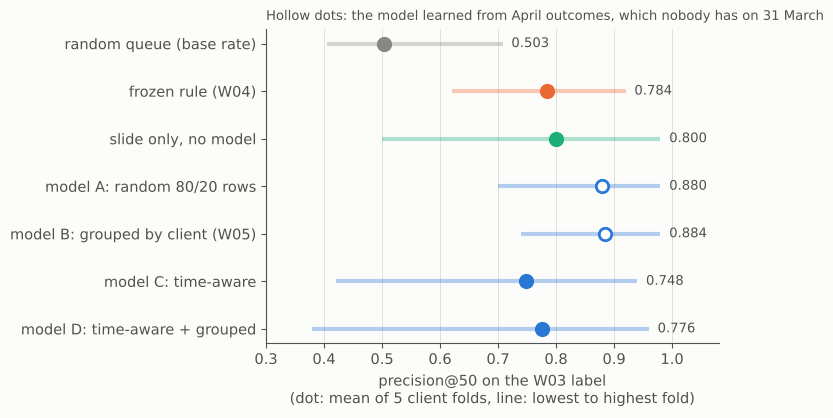

Saved ../../work/figures/capstone_fig1_validation_designs.png


In [12]:
# Paper figure style: the validated categorical slots used since W07, bigger text for a web page
SURFACE, INK, INK_2, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
plt.rcParams.update({"font.size": 10.5, "axes.edgecolor": INK_2, "axes.labelcolor": INK_2, "xtick.color": INK_2,
                     "ytick.color": INK_2, "axes.titlecolor": INK, "font.family": "sans-serif"})
PAPER_FIGS = []


def clean_axes(ax, grid_axis="y"):
    ax.set_facecolor(SURFACE)
    ax.grid(axis=grid_axis, color=GRID, linewidth=0.7)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)


def save_figure(fig, name):
    path = FIG_DIR / name
    fig.savefig(path, dpi=200, facecolor=SURFACE, bbox_inches="tight")
    PAPER_FIGS.append(path)
    plt.show()
    print(f"Saved {path}")


# The W05 → W06 story on the same March→April test pages, straight from the W06 receipt
DESIGN_ROWS = [("random queue (base rate)", "random order", "no model"),
               ("frozen rule (W04)", "W04 rule (baseline)", "no model"),
               ("slide only, no model", "slide only (no model)", "no model"),
               ("model A: random 80/20 rows", "logistic regression, A", "yes, even of the test clients"),
               ("model B: grouped by client (W05)", "logistic regression, B", "yes, of other clients"),
               ("model C: time-aware", "logistic regression, C", "no"),
               ("model D: time-aware + grouped", "logistic regression, D", "no")]
DESIGNS = pd.DataFrame([{"method": label, "learns from April outcomes?": sees,
                         **{m: get(w06, *MAR, key, m) for m in ["P@50", "avg precision", "ROC AUC"]},
                         "lowest fold P@50": min(get(w06, "mar_apr_test", "p50_per_fold", key)),
                         "highest fold P@50": max(get(w06, "mar_apr_test", "p50_per_fold", key))}
                        for label, key, sees in DESIGN_ROWS]).set_index("method")
display(DESIGNS.round(3))

# Figure 1: P@50 by validation design (dot = mean of 5 client folds, line = lowest to highest fold)
fig, ax = plt.subplots(figsize=(7.4, 4.3), facecolor=SURFACE)
clean_axes(ax, "x")
colors = [MUTED, ORANGE, AQUA, BLUE, BLUE, BLUE, BLUE]
for i, ((label, row), color) in enumerate(zip(DESIGNS.iterrows(), colors)):
    hollow = row["learns from April outcomes?"].startswith("yes")
    ax.hlines(i, row["lowest fold P@50"], row["highest fold P@50"], color=color, alpha=0.35, linewidth=3, zorder=1)
    ax.scatter(row["P@50"], i, s=80, zorder=3, facecolor=SURFACE if hollow else color, edgecolor=color, linewidth=2)
    ax.text(max(row["highest fold P@50"], row["P@50"]) + 0.015, i, f"{row['P@50']:.3f}", va="center", fontsize=9.5, color=INK_2)
ax.set_yticks(range(len(DESIGNS)), DESIGNS.index)
ax.invert_yaxis()
ax.set_xlim(0.3, 1.08)
ax.set_xlabel("precision@50 on the W03 label\n(dot: mean of 5 client folds, line: lowest to highest fold)")
ax.text(0.0, 1.02, "Hollow dots: the model learned from April outcomes, which nobody has on 31 March",
        ha="left", va="bottom", fontsize=9.5, color=INK_2, transform=ax.transAxes)
fig.tight_layout()
save_figure(fig, "capstone_fig1_validation_designs.png")

**What the table says.** With a split that hides only the test clients (B, the W05 design) the model beat the frozen rule by 10 points of P@50 (0.884 vs 0.784). Once it may learn only from labels that exist on 31 March (C and D), it falls to 0.748 and 0.776, level with the rule and below the plain slide sort (0.800). A random 80/20 row split (A) would have reported 0.880. So the honest number for March→April is the D row. The fold lines show how much one P@50 number moves with which clients are tested.

### 4b. The sealed test: what I expect before reading June

**This cell was written before June was read for the first time.** Each expectation is something that held on both earlier decision days, turned into a fixed pass/fail test. The table checks each test on 31 March and 30 April (already known). The column for 31 May is filled only after the June cell below. If a test fails on June, the paper reports it as a failure.

| # | Expectation for 31 May | Test (fixed before June) |
|---|---|---|
| H1 | every ranking beats a random queue | rule, slide-only and model (D) P@50 all at least 0.10 above the base rate |
| H2 | the model is not clearly better than the slide-only sort | model (D) P@50 minus slide-only P@50 below +0.05 |
| H3 | the model is at least level with the frozen rule | model (D) P@50 minus rule P@50 at least −0.05 |
| H4 | the playbook order finds far more lasting click loss than the model or the rule | first 50 rows: clicks a day still lost next month at least 10× the model-only order and 2× the rule |
| H5 | most of the playbook batch stays below its normal level | at least 70% of the first 50 rows still below 80% of their previous month next month (the W07 floor) |
| H6 | the previous month separates decay from an ended surge | "still below normal next month": slid-and-below pages at least 20 points above surge-ended pages |
| H7 | the W03 label does not separate them | "declined": the two groups within 10 points of each other |
| H8 | the queue does not forecast new falls | model (D) P@50 on the strict label within 0.10 of the strict base rate |

In [13]:
EXPECTATIONS_NOTE = "written before June 2026 was read; tests fixed in code, never changed after"
TESTS = {
    "H1": lambda r: min(r["model D P@50"], r["rule P@50"], r["slide P@50"]) - r["random P@50"] >= 0.10,
    "H2": lambda r: r["model D P@50"] - r["slide P@50"] < 0.05,
    "H3": lambda r: r["model D P@50"] - r["rule P@50"] >= -0.05,
    "H4": lambda r: (r["playbook clicks still lost"] >= 10 * max(r["model-only clicks still lost"], 1)
                     and r["playbook clicks still lost"] >= 2 * r["rule clicks still lost"]),
    "H5": lambda r: r["playbook still below normal"] >= 0.70,
    "H6": lambda r: r["slid-below still below normal"] - r["surge-ended still below normal"] >= 0.20,
    "H7": lambda r: abs(r["slid-below declined"] - r["surge-ended declined"]) < 0.10,
    "H8": lambda r: abs(r["model D strict P@50"] - r["strict base rate"]) < 0.10,
}
STRICT_CURVES = {}


def run_results(run):
    # The numbers every test reads, for one decision day
    c, s = CURVES[run], STRICT_CURVES[run]
    v, d = VALUE[run], DECAY[run]
    play, surge, below = "playbook: model score x clicks at stake", "slid, back to normal (surge ended)", "slid, below its normal level"
    return {"random P@50": c.loc["random order (base rate)", 50], "model D P@50": c.loc["same model, test clients held out (D)", 50],
            "model C P@50": c.loc["queue model (time-aware, C)", 50], "rule P@50": c.loc["W04 rule (frozen)", 50],
            "slide P@50": c.loc["slide only (no model)", 50],
            "playbook clicks still lost": v.loc[play, "clicks a day still lost next month"],
            "clicks-only clicks still lost": v.loc["clicks at stake only (no model)", "clicks a day still lost next month"],
            "model-only clicks still lost": v.loc["model score only", "clicks a day still lost next month"],
            "rule clicks still lost": v.loc["W04 rule (frozen)", "clicks a day still lost next month"],
            "playbook still below normal": v.loc[play, "still below normal next month"],
            "playbook declined (W03 label)": v.loc[play, "declined (W03 label)"],
            "slid-below still below normal": d.loc[below, "still below normal next month"],
            "surge-ended still below normal": d.loc[surge, "still below normal next month"],
            "slid-below declined": d.loc[below, "declined (W03 label)"], "surge-ended declined": d.loc[surge, "declined (W03 label)"],
            "strict base rate": s.loc["random order (base rate)", 50], "model D strict P@50": s.loc["same model, test clients held out (D)", 50]}


def check_expectations(runs):
    out = {}
    for run in runs:
        r = run_results(run)
        out[run] = {h: bool(test(r)) for h, test in TESTS.items()}
    return pd.DataFrame(out)


for run in EARLIER:
    STRICT_CURVES[run] = fold_mean(precision_per_fold(run, STRICT_LABEL))
BEFORE = check_expectations(EARLIER)
BEFORE[SEALED] = "not read yet"
assert "2026-06" not in MONTHS, "June was read before the expectations were fixed"
print("Expectations fixed:", EXPECTATIONS_NOTE)
display(BEFORE)
pd.DataFrame({run: run_results(run) for run in EARLIER}).round(3)

Expectations fixed: written before June 2026 was read; tests fixed in code, never changed after


,31 March,30 April,31 May
H1,True,True,not read yet
H2,True,True,not read yet
H3,True,True,not read yet
H4,True,True,not read yet
H5,True,True,not read yet
H6,True,True,not read yet
H7,True,True,not read yet
H8,True,True,not read yet


,31 March,30 April
random P@50,0.503,0.581
model D P@50,0.776,0.988
model C P@50,0.748,0.988
rule P@50,0.784,0.884
slide P@50,0.800,0.980
playbook clicks still lost,553.095,527.419
clicks-only clicks still lost,546.302,585.484
model-only clicks still lost,1.881,2.032
rule clicks still lost,45.833,105.032
playbook still below normal,0.880,0.980


### Reading June, once

June is read here for the first time and only as hindsight: the 31 May queue, its scores and its order already exist above. The W03 rule 4 (a row on every day of the label month) is applied now, for scoring only. The cell also checks that this late join gives exactly the same labels as the W07 frame code on April→May.

In [14]:
MONTHS["2026-06"] = month_pages("2026-06")      # the sealed month: first read, hindsight only
june = MONTHS["2026-06"]
print(f"June partition: {len(june):,} pages, days {june['first_date'].min():%Y-%m-%d} to {june['last_date'].max():%Y-%m-%d}")


def hindsight_after(frame, label_month):
    # Labels for an existing frame, joined after the queue is built. Pages without every day of the label month get NaN (W03 rule 4)
    l_days = pd.Timestamp(f"{label_month}-01").days_in_month
    m = frame[["content_hash_id", "imp_per_day", "late_per_day"]].merge(
        MONTHS[label_month][["content_hash_id", "n_rows", "imp", "clicks"]], on="content_hash_id", how="left")
    full = m["n_rows"].eq(l_days)
    next_per_day = (m["imp"] / l_days).where(full)
    change_pct = 100 * (next_per_day - m["imp_per_day"]) / m["imp_per_day"]
    vs_late_pct = 100 * (next_per_day - m["late_per_day"]) / m["late_per_day"].where(m["late_per_day"] > 0)
    h = pd.DataFrame({LABEL: (change_pct < DECLINE_CUTOFF_PCT).astype(float).where(full).to_numpy(),
                      STRICT_LABEL: (vs_late_pct < DECLINE_CUTOFF_PCT).astype(float).where(full).to_numpy(),
                      "next_per_day": next_per_day.to_numpy(), "next_clicks_per_day": (m["clicks"] / l_days).where(full).to_numpy()},
                     index=m["content_hash_id"])
    return h, int((~full).sum())


# Same labels as the W07 frame code? Check on April→May, where both are available
check, _ = hindsight_after(FRAMES["Apr→May"], "2026-05")
assert np.allclose(check.to_numpy(dtype=float), HIND["Apr→May"].reindex(check.index).to_numpy(dtype=float), equal_nan=True)
print("PASS  the late join gives the same labels as the W07 frame code on April→May")

HIND["May→Jun"], RULE4_REMOVED = hindsight_after(FRAMES["May→Jun"], "2026-06")
pool_june = POOLS["May→Jun"]
JUNE_FACTS = {"pages in the 31 May frame": len(FRAMES["May→Jun"]),
              "pages without every June day (left out of scoring, W03 rule 4)": RULE4_REMOVED,
              "label base rate, all frame pages": float(np.nanmean(labels("May→Jun", FRAMES["May→Jun"]))),
              "label base rate, review pool": float(np.nanmean(labels("May→Jun", pool_june))),
              "strict label base rate, review pool": float(np.nanmean(labels("May→Jun", pool_june, STRICT_LABEL))),
              "pool base rate of the training month (Apr→May)": float(labels("Apr→May", POOLS["Apr→May"]).mean())}
pd.Series(JUNE_FACTS).round(4)

June partition: 409,205 pages, days 2026-06-01 to 2026-06-30


PASS  the late join gives the same labels as the W07 frame code on April→May


pages in the 31 May frame                                         106609.0000
pages without every June day (left out of scoring, W03 rule 4)      3293.0000
label base rate, all frame pages                                       0.6576
label base rate, review pool                                           0.6407
strict label base rate, review pool                                    0.6461
pool base rate of the training month (Apr→May)                         0.5729
dtype: float64

**A data check on June.** June is the last month of the release. The newest days of any export are the most likely to be incomplete (the release already cut the freshest 3 days for that reason). If the end of June were still missing data, pages would look like they "declined" for a technical reason. The cell below compares daily totals across May and June for the whole partition.

In [15]:
daily = con.sql(f'''
    SELECT report_date, SUM(gsc_impressions)::BIGINT AS impressions, SUM(gsc_clicks)::BIGINT AS clicks,
           COUNT(*) AS rows_, COUNT(*) FILTER (WHERE gsc_data_available IS TRUE) AS gsc_rows
    FROM read_parquet(['{REL}/fact_content_daily_performance/month=2026-05/*.parquet',
                       '{REL}/fact_content_daily_performance/month=2026-06/*.parquet'])
    GROUP BY report_date ORDER BY report_date
''').df()
daily["report_date"] = pd.to_datetime(daily["report_date"])
daily["part"] = np.select([daily["report_date"] < "2026-06-01", daily["report_date"] < "2026-06-24"],
                          ["May, all days", "June 1 to 23"], default="June 24 to 30 (newest week)")
JUNE_CHECK = daily.groupby("part", sort=False)[["impressions", "clicks", "rows_", "gsc_rows"]].mean().round(0)
JUNE_CHECK["impressions vs May"] = JUNE_CHECK["impressions"] / JUNE_CHECK.loc["May, all days", "impressions"]
JUNE_CHECK["GSC rows vs May"] = JUNE_CHECK["gsc_rows"] / JUNE_CHECK.loc["May, all days", "gsc_rows"]
print("Daily averages over the whole partition (all pages, all clients)")
JUNE_CHECK.round(3)

Daily averages over the whole partition (all pages, all clients)


,impressions,clicks,rows_,gsc_rows,impressions vs May,GSC rows vs May
part,,,,,,
"May, all days",8585964.0,29815.0,377012.0,141078.0,1.000,1.000
June 1 to 23,7293330.0,39986.0,398081.0,129365.0,0.849,0.917
June 24 to 30 (newest week),6921183.0,41349.0,362601.0,129077.0,0.806,0.915


**What the check shows.** Across the whole partition June had about 15% fewer impressions a day than May (0.849 of the May level on 1 to 23 June and 0.806 in the newest week) and about 8% fewer page-days with GSC data, while clicks a day were higher than in May. The newest week is only a little lower than the rest of June, so this does not look like missing days at the end of the export. It looks like a drop across the whole portfolio in June. I can't tell from this data whether it comes from search demand or from tracking.

It matters for reading the sealed test: June has the highest base rate of the three months, so part of every June "decline" is this broad shift. That is why the results below are also read as **lift over the base rate**, not only as raw precision.

### 4c. Three decision days side by side

The same evaluation as W06 and W07, now with the sealed day: precision@K on the W03 label inside each of the five client folds, the batch value of five orders on the same rows and the decay table. Then the eight expectations are checked.

In [16]:
FOLDS[SEALED] = precision_per_fold(SEALED)
CURVES[SEALED] = fold_mean(FOLDS[SEALED])
STRICT_CURVES[SEALED] = fold_mean(precision_per_fold(SEALED, STRICT_LABEL))
VALUE[SEALED], VALUE_CURVES[SEALED] = batch_value(SEALED)
DECAY[SEALED] = decay_table(SEALED)
SCORED_ROWS = {run: len(judged_rows(run)) for run in RUNS}
NEED_PERSON = {run: int(PLAYBOOK[run]["action"].isin(NEEDS_PERSON).sum()) for run in RUNS}
print("Rows that need a person / of them with a full label month:", {run: f"{NEED_PERSON[run]:,} / {SCORED_ROWS[run]:,}" for run in RUNS})

P50 = pd.DataFrame({run: CURVES[run][50] for run in RUNS})
P50.loc["model D, lowest to highest fold"] = [f"{FOLDS[run].query('method == \"same model, test clients held out (D)\"')[50].min():.2f} to "
                                              f"{FOLDS[run].query('method == \"same model, test clients held out (D)\"')[50].max():.2f}" for run in RUNS]
print("Precision@50 on the W03 label, mean of 5 client folds (31 May = sealed test)")
display(P50)

LIFT = pd.DataFrame({run: CURVES[run][50] - CURVES[run].loc["random order (base rate)", 50] for run in RUNS}).drop("random order (base rate)")
print("P@50 minus the base rate of the same folds (the lift a reviewer actually gets)")
display(LIFT.round(3))
batch_ids = PLAYBOOK[SEALED].loc[PLAYBOOK[SEALED]["in_first_batch"], "content_hash_id"]
BATCH_WITHOUT_JUNE = int(HIND["May→Jun"]["next_per_day"].reindex(batch_ids).isna().sum())
print(f"31 May batch rows without a full June (replaced by the next rows when scoring the first 50): {BATCH_WITHOUT_JUNE}")

RESULTS = {run: run_results(run) for run in RUNS}
AFTER = check_expectations(RUNS)
print("Expectations (fixed before June was read): did each one hold?")
display(AFTER)
pd.DataFrame(RESULTS).round(3)

Rows that need a person / of them with a full label month: {'31 March': '25,472 / 25,472', '30 April': '40,102 / 40,102', '31 May': '38,055 / 37,378'}
Precision@50 on the W03 label, mean of 5 client folds (31 May = sealed test)


,31 March,30 April,31 May
method,,,
random order (base rate),0.503439,0.58111,0.636822
"queue model (time-aware, C)",0.748,0.988,0.944
"same model, test clients held out (D)",0.776,0.988,0.944
W04 rule (frozen),0.784,0.884,0.936
slide only (no model),0.8,0.98,0.92
"model D, lowest to highest fold",0.38 to 0.96,0.98 to 1.00,0.90 to 0.98


P@50 minus the base rate of the same folds (the lift a reviewer actually gets)


,31 March,30 April,31 May
method,,,
"queue model (time-aware, C)",0.245,0.407,0.307
"same model, test clients held out (D)",0.273,0.407,0.307
W04 rule (frozen),0.281,0.303,0.299
slide only (no model),0.297,0.399,0.283


31 May batch rows without a full June (replaced by the next rows when scoring the first 50): 0
Expectations (fixed before June was read): did each one hold?


,31 March,30 April,31 May
H1,True,True,True
H2,True,True,True
H3,True,True,True
H4,True,True,True
H5,True,True,True
H6,True,True,True
H7,True,True,True
H8,True,True,True


,31 March,30 April,31 May
random P@50,0.503,0.581,0.637
model D P@50,0.776,0.988,0.944
model C P@50,0.748,0.988,0.944
rule P@50,0.784,0.884,0.936
slide P@50,0.800,0.980,0.920
playbook clicks still lost,553.095,527.419,694.533
clicks-only clicks still lost,546.302,585.484,756.633
model-only clicks still lost,1.881,2.032,38.100
rule clicks still lost,45.833,105.032,139.867
playbook still below normal,0.880,0.980,0.940


**What the sealed month says. All eight expectations held on 31 May.**

- **Every ranking beat a random queue by a wide margin.** P@50 was 0.944 for the model (D), 0.936 for the frozen rule and 0.920 for the slide-only sort, against a base rate of 0.637. As lift over the base rate that is +0.307, +0.299 and +0.283, close to the earlier months.
- **The model was level with the simple methods again.** Its folds were much steadier than on 31 March (0.90 to 0.98 vs 0.38 to 0.96), but the gap to the rule is less than one page out of 50.
- **The queue still does not forecast new falls.** On the strict label (did the page fall another 20% after 31 May?) the model's top 50 scored 0.628 against a strict base rate of 0.642.
- **3,293 of the 106,609 pages (3.1%) had no full June** and are left out of the scoring. None of them was in the first batch. In March and April this rule removed 0 pages.

In [17]:
# The 31 May batch value, five orders on the same rows (June is hindsight)
print(f"31 May: first {BATCH} rows of each order, out of {SCORED_ROWS[SEALED]:,} rows that need a person and have a full June")
display(VALUE[SEALED].round(3))
print("Decay table, 31 May review pool (June is hindsight)")
DECAY[SEALED].round(3)

31 May: first 50 rows of each order, out of 37,378 rows that need a person and have a full June


,declined (W03 label),fell another 20% (strict),still below normal next month,clicks a day at stake on the day,clicks a day still lost next month,rows with 0 clicks this month,biggest single-client share
playbook: model score x clicks at stake,0.82,0.64,0.94,556.388,694.533,0.00,0.32
model score only,0.94,0.60,0.88,38.829,38.100,0.30,0.36
clicks at stake only (no model),0.74,0.62,0.94,592.021,756.633,0.00,0.40
W04 rule (frozen),0.94,0.52,0.82,70.321,139.867,0.00,0.32
slide only (no model),0.98,0.64,0.98,98.812,98.500,0.08,0.86


Decay table, 31 May review pool (June is hindsight)


,pages,share of pool,declined (W03 label),fell another 20% (strict),still below normal next month
"slid, below its normal level",18466.0,0.209,0.807,0.663,0.936
"slid, back to normal (surge ended)",4716.0,0.053,0.822,0.717,0.652
"no slide, already below normal",19785.0,0.224,0.588,0.611,0.885
"no slide, at or above normal",34066.0,0.385,0.588,0.672,0.477
"young page, slid",3151.0,0.036,0.762,0.571,NaN
"young page, no slide",8281.0,0.094,0.464,0.571,NaN


**The batch on 31 May.** The playbook's first 50 rows held **695 clicks a day that were still lost in June**, against 38 for the model-only order and 140 for the frozen rule. Of its rows, 94% were still below their normal level a month later.

**One result did not go the playbook's way.** The plain clicks-at-stake order (no model) held more lost clicks (757) with the same persistence (94%). Over three months the clicks-only order found more lasting click loss twice (585 vs 527 on 30 April, 757 vs 695 on 31 May) and a little less once (546 vs 553 on 31 March). The model weight added persistence on 31 March (+12 points) and 30 April (+4) and nothing in June. So **the clicks at stake carry the value of the batch and the model weight is a small extra that has not clearly earned its place.** The W07 fallback (drop the model weight after two months in a row where the playbook is less persistent) has not fired, because June was a tie, not a loss.

**The decay table repeats the W07 finding with a smaller gap.** 93.6% of the pages that slid and sat below their normal level were still below normal in June, against 65.2% of the pages whose slide was a surge ending. The gap (28 points) is smaller than on 31 March and 30 April (43 and 54 points) because in June far more pages of every kind ended below normal, including 47.7% of the steady pages (27.2% and 28.4% before). That fits the portfolio-wide drop in the data check.

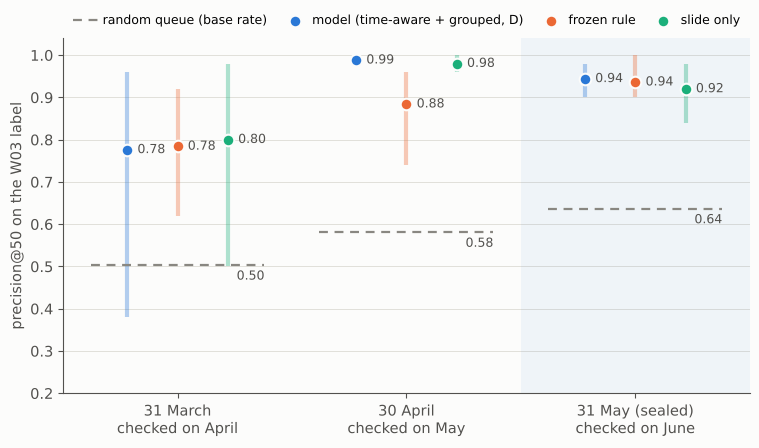

Saved ../../work/figures/capstone_fig2_three_decision_days.png


In [18]:
# Figure 2: P@50 on three decision days (dot = mean of 5 client folds, line = lowest to highest fold)
METHODS = [("same model, test clients held out (D)", BLUE, "model (time-aware + grouped, D)"),
           ("W04 rule (frozen)", ORANGE, "frozen rule"), ("slide only (no model)", AQUA, "slide only")]
fig, ax = plt.subplots(figsize=(8, 4.6), facecolor=SURFACE)
clean_axes(ax)
ax.axvspan(1.5, 2.5, color=BLUE, alpha=0.06, linewidth=0)
for i, run in enumerate(RUNS):
    base = CURVES[run].loc["random order (base rate)", 50]
    ax.hlines(base, i - 0.38, i + 0.38, color=MUTED, linestyle=(0, (4, 3)), linewidth=1.6, label="random queue (base rate)" if i == 0 else None)
    ax.text(i + 0.38, base - 0.012, f"{base:.2f}", ha="right", va="top", fontsize=9, color=INK_2)
    for off, (method, color, short) in zip([-0.22, 0.0, 0.22], METHODS):
        vals = FOLDS[run].loc[FOLDS[run]["method"] == method, 50]
        ax.vlines(i + off, vals.min(), vals.max(), color=color, alpha=0.35, linewidth=3, zorder=1)
        ax.scatter(i + off, vals.mean(), s=70, color=color, edgecolor=SURFACE, linewidth=1.5, zorder=3, label=short if i == 0 else None)
        ax.text(i + off + 0.045, vals.mean(), f"{vals.mean():.2f}", va="center", fontsize=9, color=INK_2)
ax.set_xticks(range(3), ["31 March\nchecked on April", "30 April\nchecked on May", "31 May (sealed)\nchecked on June"])
ax.set_xlim(-0.5, 2.5)
ax.set_ylim(0.2, 1.04)
ax.set_ylabel("precision@50 on the W03 label")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=4, frameon=False, fontsize=9, handletextpad=0.4, columnspacing=1.2)
fig.tight_layout()
save_figure(fig, "capstone_fig2_three_decision_days.png")

**Figure 2.** Every method beats a random queue on all three days. On no day is the model clearly ahead of the frozen rule and the slide sort. The base rate climbs each month (0.50, 0.58, 0.64), which is part of why the raw numbers climb too.

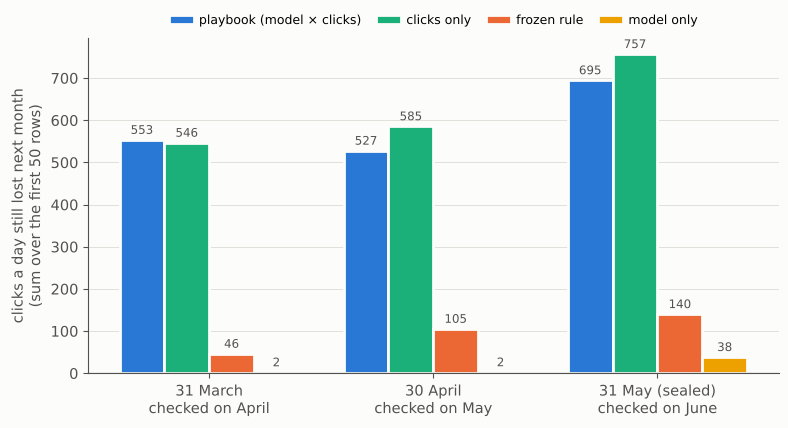

Saved ../../work/figures/capstone_fig3_batch_value.png


In [19]:
# Figure 3: clicks a day still lost next month, summed over the first 50 rows of each order (hindsight)
ORDER_STYLE = [("playbook: model score x clicks at stake", BLUE, "playbook (model × clicks)"),
               ("clicks at stake only (no model)", AQUA, "clicks only"),
               ("W04 rule (frozen)", ORANGE, "frozen rule"), ("model score only", YELLOW, "model only")]
fig, ax = plt.subplots(figsize=(8, 4.4), facecolor=SURFACE)
clean_axes(ax)
width = 0.2
for j, (order, color, short) in enumerate(ORDER_STYLE):
    vals = [VALUE[run].loc[order, "clicks a day still lost next month"] for run in RUNS]
    xs = np.arange(3) + (j - 1.5) * width
    ax.bar(xs, vals, width=width, color=color, edgecolor=SURFACE, linewidth=2, label=short)
    for x, v in zip(xs, vals):
        ax.text(x, max(v, 0) + 8, f"{v:,.0f}", ha="center", va="bottom", fontsize=8.5, color=INK_2)
ax.axhline(0, color=INK_2, linewidth=0.8)
ax.set_xticks(range(3), ["31 March\nchecked on April", "30 April\nchecked on May", "31 May (sealed)\nchecked on June"])
ax.set_ylabel("clicks a day still lost next month\n(sum over the first 50 rows)")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=4, frameon=False, fontsize=9, handletextpad=0.4, columnspacing=1.2)
fig.tight_layout()
save_figure(fig, "capstone_fig3_batch_value.png")

**Figure 3.** The value of a 50-row batch comes from ordering by clicks at stake. The model on its own finds almost no lasting click loss (2, 2 and 38 clicks a day). The frozen rule finds 46 to 140.

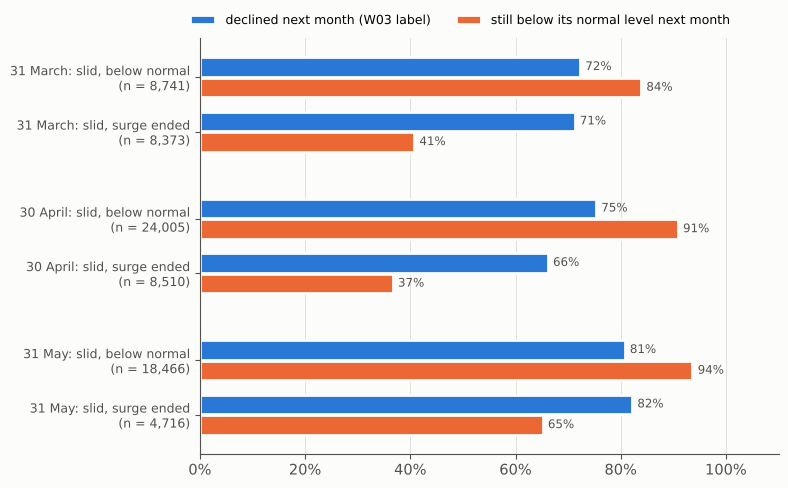

Saved ../../work/figures/capstone_fig4_decay_vs_surge.png


In [20]:
# Figure 4: the W03 label vs the page's own previous month, for the two kinds of pages that slid (hindsight)
KINDS = [("slid, below its normal level", "slid, below normal"), ("slid, back to normal (surge ended)", "slid, surge ended")]
fig, ax = plt.subplots(figsize=(8, 5.0), facecolor=SURFACE)
clean_axes(ax, "x")
ax.grid(axis="y", visible=False)
ypos, ylabels = [], []
for i, run in enumerate(RUNS):
    for j, (kind, short) in enumerate(KINDS):
        y = i * 2.6 + j
        ypos.append(y)
        ylabels.append(f"{run}: {short}\n(n = {int(DECAY[run].loc[kind, 'pages']):,})")
        for off, column, color, name in [(-0.19, "declined (W03 label)", BLUE, "declined next month (W03 label)"),
                                         (0.19, "still below normal next month", ORANGE, "still below its normal level next month")]:
            v = DECAY[run].loc[kind, column]
            ax.barh(y + off, v, height=0.36, color=color, edgecolor=SURFACE, linewidth=2, label=name if (i, j) == (0, 0) else None)
            ax.text(v + 0.01, y + off, f"{v:.0%}", va="center", fontsize=8.5, color=INK_2)
ax.set_yticks(ypos, ylabels, fontsize=9)
ax.invert_yaxis()
ax.set_xlim(0, 1.1)
ax.xaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0))
ax.legend(loc="lower center", bbox_to_anchor=(0.45, 1.0), ncol=2, frameon=False, fontsize=9)
fig.tight_layout()
save_figure(fig, "capstone_fig4_decay_vs_surge.png")

**Figure 4.** The W03 label scores a surge that ended about the same as a real drop below normal on every day (72% vs 71%, 75% vs 66%, 81% vs 82%). The page's own previous month tells them apart on every day, with a smaller gap in June.

### The W07 monitoring checks on the sealed run

W07 proposed two clocks: checks that can run on the decision day (pre-release) and checks that need next month's labels (post-label). Here they run on 31 May with the same thresholds. The fallback rule ("model below the frozen rule two labeled months in a row → drop the model") is checked over all three labeled months.

In [21]:
def psi(reference, current, bins=10):
    # Population stability index of one feature: current month vs reference month, on reference deciles (W07)
    ref, cur = pd.Series(reference).dropna(), pd.Series(current).dropna()
    edges = np.unique(np.quantile(ref, np.linspace(0, 1, bins + 1)))
    edges[0], edges[-1] = -np.inf, np.inf
    r = np.clip(np.histogram(ref, edges)[0] / len(ref), 1e-4, None)
    c = np.clip(np.histogram(cur, edges)[0] / len(cur), 1e-4, None)
    return float(np.sum((c - r) * np.log(c / r)))


THRESHOLDS = get(w07, "monitoring", "thresholds_proposed")
s, ref = RUN_SLICE[SEALED], TRAIN_SLICE[SEALED]
q, cur_pool, ref_pool = PLAYBOOK[SEALED], POOLS[s], POOLS[ref]
batch_now = q[q["in_first_batch"]]
PRE = {"pool size change vs last run": len(cur_pool) / len(ref_pool) - 1,
       **{f"PSI {f}": psi(ref_pool[f], cur_pool[f]) for f in FEATURES},
       "share of pool pages off the queue as young": (q.loc[q["in_pool"], "action"] == "wait_and_recheck").mean(),
       "clients with a site-wide drop": int(q.loc[q["action"] == "site_check_first", "client_hash_id"].nunique()),
       "biggest single-client share of the batch": batch_now["client_hash_id"].value_counts().iloc[0] / BATCH}
POST = {"base-rate move vs the training month": JUNE_FACTS["label base rate, review pool"] - JUNE_FACTS["pool base rate of the training month (Apr→May)"],
        "model C P@50 minus frozen rule P@50": RESULTS[SEALED]["model C P@50"] - RESULTS[SEALED]["rule P@50"],
        "batch still below normal next month": RESULTS[SEALED]["playbook still below normal"],
        "playbook minus clicks-only on persistence": RESULTS[SEALED]["playbook still below normal"]
        - VALUE[SEALED].loc["clicks at stake only (no model)", "still below normal next month"]}
TRIGGERS_MAY = pd.DataFrame([
    ("pre-release", "pool size moved more than 25%", abs(PRE["pool size change vs last run"]), abs(PRE["pool size change vs last run"]) > THRESHOLDS["pool size change vs last run"]),
    ("pre-release", "a feature PSI above 0.25", max(PRE[f"PSI {f}"] for f in FEATURES), max(PRE[f"PSI {f}"] for f in FEATURES) > THRESHOLDS["feature PSI"]),
    ("pre-release", "more than 25% of pool pages are young", PRE["share of pool pages off the queue as young"], PRE["share of pool pages off the queue as young"] > THRESHOLDS["share of pool pages off the queue as young"]),
    ("pre-release", "at least one client with a site-wide drop", PRE["clients with a site-wide drop"], PRE["clients with a site-wide drop"] >= THRESHOLDS["clients with a site-wide drop"]),
    ("pre-release", "one client holds more than half of the batch", PRE["biggest single-client share of the batch"], PRE["biggest single-client share of the batch"] > THRESHOLDS["biggest single-client share of the batch"]),
    ("post-label", "base rate moved more than 0.10 vs the training month", abs(POST["base-rate move vs the training month"]), abs(POST["base-rate move vs the training month"]) > THRESHOLDS["base-rate move vs the training month"]),
    ("post-label", "model P@50 below the frozen rule", POST["model C P@50 minus frozen rule P@50"], POST["model C P@50 minus frozen rule P@50"] < 0),
    ("post-label", "batch still below normal under 70%", POST["batch still below normal next month"], POST["batch still below normal next month"] < THRESHOLDS["batch still below normal next month (floor)"]),
    ("post-label", "playbook below clicks-only on persistence", POST["playbook minus clicks-only on persistence"], POST["playbook minus clicks-only on persistence"] < 0),
], columns=["clock", "trigger", "31 May value", "fired"]).set_index(["clock", "trigger"])
worst = max(FEATURES, key=lambda f: PRE[f"PSI {f}"])
print(f"Worst PSI feature on 31 May: {worst} ({PRE['PSI ' + worst]:.3f})")
display(TRIGGERS_MAY.round(3))

BELOW_RULE = {run: bool(get(w07, "monitoring", "post_label", run, "model P@50 (C, fold mean)") < get(w07, "monitoring", "post_label", run, "frozen rule P@50 (fold mean)"))
              for run in EARLIER}
BELOW_RULE[SEALED] = bool(RESULTS[SEALED]["model C P@50"] < RESULTS[SEALED]["rule P@50"])
two_in_a_row = any(a and b for a, b in zip(list(BELOW_RULE.values()), list(BELOW_RULE.values())[1:]))
print("Queue model (C) below the frozen rule on P@50:", BELOW_RULE, "->", "fallback TRIGGERED" if two_in_a_row else "fallback not triggered")

Worst PSI feature on 31 May: avg_position (0.265)


31 May value  \
clock       trigger                                                            
pre-release pool size moved more than 25%                              0.065   
            a feature PSI above 0.25                                   0.265   
            more than 25% of pool pages are young                      0.130   
            at least one client with a site-wide drop                  8.000   
            one client holds more than half of the batch               0.320   
post-label  base rate moved more than 0.10 vs the training ...         0.068   
            model P@50 below the frozen rule                           0.008   
            batch still below normal under 70%                         0.940   
            playbook below clicks-only on persistence                  0.000   

                                                                fired  
clock       trigger                                                    
pre-release pool size moved more than 25%                       False  
            a feature PSI above 0.25                             True  
            more than 25% of pool pages are young               False  
            at least one client with a site-wide drop            True  
            one client holds more than half of the batch        False  
post-label  base rate moved more than 0.10 vs the training ...  False  
            model P@50 below the frozen rule                    False  
            batch still below normal under 70%                  False  
            playbook below clicks-only on persistence           False

Queue model (C) below the frozen rule on P@50: {'31 March': True, '30 April': False, '31 May': False} -> fallback not triggered


**What the monitoring would have said on 31 May.** Two pre-release triggers fire: `avg_position` drifted against April (PSI 0.265) and 8 clients had their whole second half of May under 80% of April, which sends 14,596 pages to site checks. After June's labels nothing fires: the base rate moved 0.068 against the training month (under the 0.10 alarm), the queue model was 0.008 above the rule and 94% of the batch stayed below normal. The fallback is not triggered, because the model was below the rule only on 31 March.

### Results in one table

| | 31 March | 30 April | 31 May (sealed) |
|---|---|---|---|
| base rate (random queue P@50) | 0.503 | 0.581 | 0.637 |
| frozen rule P@50 | 0.784 | 0.884 | 0.936 |
| slide-only sort P@50 | 0.800 | 0.980 | 0.920 |
| model (time-aware + grouped, D) P@50 | 0.776 | 0.988 | 0.944 |
| model (D) P@50 on the strict label (its base rate) | 0.496 (0.508) | 0.480 (0.509) | 0.628 (0.642) |
| first 50 rows, clicks a day still lost next month: playbook | 553 | 527 | 695 |
| clicks-only order | 546 | 585 | 757 |
| frozen rule order | 46 | 105 | 140 |
| model-only order | 2 | 2 | 38 |
| playbook batch still below normal next month | 88% | 98% | 94% |
| expectations held | 8 of 8 (known) | 8 of 8 (known) | **8 of 8 (sealed)** |

**The claim this supports, at the right strength:** measured on clients the model never saw and on a month nobody had looked at, a queue built from last month's search numbers put pages with lasting visit losses in front of a reviewer: between 527 and 757 clicks a day still lost a month later, in 50 rows, depending on the month and the order. The model does not beat a simple rule or a slide sort at finding "declined" pages. Nothing here forecasts a new fall or shows that a refresh would bring visits back.

## 5. Limitations

*What this work cannot claim.*

**What this work cannot claim**, with the number behind each limit in the cell below:

1. **Nothing here is causal.** The queue points at visits that were lost and stayed lost. No refresh was run, so nothing shows that a refresh, a new title or any other change would bring them back. The honest test is a controlled one: refresh part of a batch, leave comparable pages alone and compare them 30, 60 and 90 days later.
2. **Three decision days, one of them clean.** March and April were used to build the playbook, so only June is an untouched check. Three months is thin. A rolling backtest over more months is the most useful missing experiment.
3. **The label is a proxy and partly restates the month.** "Declined" compares next month with this month's average, so a page that already fell late in the month and stayed down counts as a hit (43% of the W05 top-50 hits, W06). On the strict label the model sits at the base rate on all three days (and the rule and the slide sort were below it in W06). The queue finds losses that already happened. It is not a forecast.
4. **June had a portfolio-wide drop** (about 15% fewer impressions a day than May, more clicks) that I can't explain from this data. It raises the June base rate and part of every June "decline".
5. **One month is a short normal level.** If the previous month was itself unusual, "below normal" is wrong for that page.
6. **Coverage.** The frames hold 38 to 45 of the 104 clients. Pages under the volume floor, young pages and clients without a full previous month are not judged at all, so absence from the queue is not a sign of health.
7. **Concentration.** Three clients hold about half of the pages and one client can fill a third of a batch, so every number leans on a few sites.
8. **Survivorship.** The frame keeps pages with a row on every day. Pages that vanished are not in it (3,293 pages had no full June).
9. **The model score is not calibrated.** It is used to order rows, never as a probability: its mean on the 31 May pool was 0.486 while 64.1% of the pool declined.

**Public-safe by construction:** the release is pseudonymized, ids are used only for grouping and splits, clients appear by rank only and the paper shows aggregates only.

In [22]:
# The numbers behind each limitation (31 May frame unless named)
frame_may = FRAMES["May→Jun"]
pages_per_client = frame_may.groupby("client_hash_id").size().sort_values(ascending=False)
pool_may = POOLS["May→Jun"]
y_pool = labels("May→Jun", pool_may)
LIMITS = pd.Series({
    "decision days with hindsight (of them sealed)": f"{len(RUNS)} ({1})",
    "clients in the 31 May frame / in the release": f"{COVERAGE[SEALED]} / {N_CLIENTS_RELEASE}",
    "top 3 clients' share of 31 May frame pages": f"{pages_per_client.head(3).sum() / pages_per_client.sum():.1%}",
    "biggest single-client share of the 31 May batch": f"{PRE['biggest single-client share of the batch']:.0%}",
    "31 May pool pages off the queue as young (no full April)": f"{PRE['share of pool pages off the queue as young']:.1%}",
    "31 May frame pages left out of scoring (no full June)": f"{RULE4_REMOVED:,}",
    "queue model: mean score on the 31 May pool vs share that declined in June": f"{QUEUE_MODEL[SEALED].predict_proba(pool_may[FEATURES])[:, 1].mean():.3f} vs {np.nanmean(y_pool):.3f}",
    "strict label, model D P@50 vs strict base rate (31 May)": f"{RESULTS[SEALED]['model D strict P@50']:.3f} vs {RESULTS[SEALED]['strict base rate']:.3f}",
    "playbook batch rows labeled 'declined' (31 May)": f"{RESULTS[SEALED]['playbook declined (W03 label)']:.0%}",
})
LIMITS.to_frame("number")

,number
decision days with hindsight (of them sealed),3 (1)
clients in the 31 May frame / in the release,45 / 104
top 3 clients' share of 31 May frame pages,49.4%
biggest single-client share of the 31 May batch,32%
31 May pool pages off the queue as young (no full April),13.0%
31 May frame pages left out of scoring (no full June),"3,293"
queue model: mean score on the 31 May pool vs share that declined in June,0.486 vs 0.641
"strict label, model D P@50 vs strict base rate (31 May)",0.628 vs 0.642
playbook batch rows labeled 'declined' (31 May),82%


## 6. Ranked recommendations

*The action playbook output — the paper's recommendations section.*

**The playbook as ranked recommendations.** What a content team should do each month, in this order, with the reason for each step:

1. **Rebuild the queue a few days after month end** (GSC data arrives 2 to 3 days late) and take the first 50 rows that need a person. The batch is small on purpose: on 31 May it was 50 of 38,055 rows that need a person but held 8.5% of all their clicks at stake.
2. **Start with the site checks.** When a whole client is down 20% or more against last month, open one ticket per client before touching single pages (`site_check_first`). A site-wide change explains many pages at once.
3. **Then the `review_for_refresh` rows:** the page slid inside the month and sits below its own normal level. Go through the five review questions, write down what is out of date or missing and only then plan a change.
4. **Then the `investigate_quiet_risk` rows:** clicks fell against last month without a slide. Check the title, the snippet and the results page first, because the impressions may have held while the clicks fell.
5. **`verify_then_review` rows first get a tracking and campaign check**, because one day holds 30% or more of the first half.
6. **Leave `monitor_only` pages alone.** Their slide was a surge ending and they are back at their normal level.
7. **Wait on young pages** (`wait_and_recheck`) until they have a full month of history. Short dips on new pages caused most false alarms (W05, W06).
8. **Keep the order simple.** Clicks lost against the page's own previous month carry the value. Keep the model weight only while the monthly check keeps it ahead of the clicks-only order.
9. **Never automate the change.** No automatic rewrite, prune, redirect, noindex or bulk title edit from this queue.
10. **Log every decision** (accept or reject, why, what changed, the date). That log is what a future before/after test of refreshes needs.

In [23]:
# The 31 May playbook: the latest queue a team would have worked through in June
q = PLAYBOOK[SEALED].copy()
client_pages = q.groupby("client_hash_id").size().reset_index(name="n").sort_values(["n", "client_hash_id"], ascending=[False, True])
CLIENT_RANK = pd.Series(np.arange(1, len(client_pages) + 1), index=client_pages["client_hash_id"].to_numpy())
q["client_rank"] = q["client_hash_id"].map(CLIENT_RANK)
ACTION_TABLE = (q.groupby("action").agg(pages=("content_hash_id", "size"), in_first_batch=("in_first_batch", "sum"),
                                        median_clicks_at_stake=("clicks_at_stake_per_day", "median"))
                .reindex(ACTIONS))
ACTION_TABLE["share of pages"] = ACTION_TABLE["pages"] / len(q)
ACTION_TABLE["needs a person"] = [ACTIONS[a][0] for a in ACTION_TABLE.index]
ACTION_TABLE["what it asks"] = [ACTIONS[a][1] for a in ACTION_TABLE.index]
with pd.option_context("display.max_colwidth", 110, "display.width", 250):
    display(ACTION_TABLE.round(3))

batch = q[q["in_first_batch"]]
BATCH_FACTS = {"pages on the queue": int(q["queue_rank"].notna().sum()), "rows that need a person": NEED_PERSON[SEALED],
               "first batch actions": {a: int(n) for a, n in batch["action"].value_counts().items()},
               "clients in the first batch": int(batch["client_rank"].nunique()),
               "biggest client in the batch": f"client rank {batch['client_rank'].value_counts().index[0]} with {batch['client_rank'].value_counts().iloc[0]} rows",
               "context codes in the batch": {c: int(batch["context_codes"].str.contains(c).sum()) for c in
                                              ["below_normal_level", "back_to_normal", "clicks_down", "low_ctr_for_position", "one_day_spike", "site_wide_drop"]},
               "clients behind the site_check_first rows of the batch": int(batch.loc[batch["action"] == "site_check_first", "client_rank"].nunique()),
               "clicks a day at stake in the batch": float(batch["clicks_at_stake_per_day"].sum()),
               "share of all clicks at stake held by the batch": float(batch["clicks_at_stake_per_day"].sum() / q.loc[q["action"].isin(NEEDS_PERSON), "clicks_at_stake_per_day"].sum())}
for k, v in BATCH_FACTS.items():
    print(f"{k}: {v}")


def review_card(row):
    # What a reviewer gets for one row: the numbers known on the day, the reason, the action and the questions (W07)
    return "\n".join([
        f"Queue rank {int(row['queue_rank'])} | client rank {int(row['client_rank'])} | action: {row['action']}",
        f"Reason (frozen rule): {row['reason_code']} | context: {row['context_codes']}",
        f"Model score {row['model_score']:.3f} (ordering score, not a probability) | clicks at stake {row['clicks_at_stake_per_day']:.1f} a day",
        f"Impressions a day: April {row['prev_per_day']:,.0f} | 1 to 15 May {row['early_per_day']:,.0f} | 16 to 31 May {row['late_per_day']:,.0f} ({row['late_vs_prev']:.0%} of normal)",
        f"Clicks a day: April {row['prev_clicks_per_day']:.1f} | 16 to 31 May {row['clicks_late_per_day']:.1f} | CTR {row['ctr_pct']:.2f}% at position {row['avg_position']:.1f}",
        "Before any change: 1) daily chart vs last month: real drop or one event?  2) season, campaign or site change?",
        "  3) does the page still match what people search for?  4) is the client changing things right now?",
        "  5) did a sibling page gain what this one lost?  Log: accept / reject, why, what was done, date"])


print()
print(review_card(batch.iloc[0]))

# The queue file a reviewer would open (pseudonymous ids, regenerated, gitignored: work/**/*.csv)
EXPORT_COLUMNS = ["decision_day", "queue_rank", "in_first_batch", "action", "reason_code", "context_codes", "model_score",
                  "clicks_at_stake_per_day", "priority", "content_hash_id", "client_hash_id", "client_rank", "prev_per_day",
                  "early_per_day", "late_per_day", "late_vs_prev", "slide_pct", "prev_clicks_per_day", "clicks_late_per_day",
                  "ctr_pct", "tier_median_ctr_pct", "avg_position"]
QUEUE_PATH = OUT_DIR / "capstone_queue_2026-05-31.csv"
q[EXPORT_COLUMNS].round(4).to_csv(QUEUE_PATH, index=False)
assert not any(c in pd.read_csv(QUEUE_PATH, nrows=1).columns for c in [LABEL, STRICT_LABEL, "next_per_day", "next_clicks_per_day"])
print(f"\nWrote {QUEUE_PATH} ({len(q):,} pages, gitignored)")

,pages,in_first_batch,median_clicks_at_stake,share of pages,needs a person,what it asks
action,,,,,,
review_for_refresh,10319,12,0.008,0.097,True,"the rule fired and the page sits below its own normal level: read the page, check the review questions, de..."
investigate_quiet_risk,12701,10,0.067,0.119,True,the rule gives NO_FLAG but clicks were lost: find out why before any change
verify_then_review,439,6,0.033,0.004,True,"one day holds 30%+ of the first half: check tracking, campaigns and the daily chart first"
site_check_first,14596,22,0.038,0.137,True,the whole client is down 20%+: one site-level check before page work
monitor_only,4853,0,0.000,0.046,False,the rule fired but the page is back at its normal level after a surge: nobody edits it
no_action,35583,0,0.000,0.334,False,the rule gives NO_FLAG and no clicks were lost: off the queue
wait_and_recheck,11703,0,NaN,0.110,False,"no full previous month (new or newly tracked page): off the queue, scored again next month"
not_in_review_pool,16415,0,0.000,0.154,False,under 5 impressions a day in the second half: off the queue (W05 pool)


pages on the queue: 42908
rows that need a person: 38055
first batch actions: {'site_check_first': 22, 'review_for_refresh': 12, 'investigate_quiet_risk': 10, 'verify_then_review': 6}
clients in the first batch: 8
biggest client in the batch: client rank 7 with 16 rows
context codes in the batch: {'below_normal_level': 47, 'back_to_normal': 3, 'clicks_down': 50, 'low_ctr_for_position': 3, 'one_day_spike': 6, 'site_wide_drop': 23}
clients behind the site_check_first rows of the batch: 4
clicks a day at stake in the batch: 556.3875
share of all clicks at stake held by the batch: 0.08487624796045426

Queue rank 1 | client rank 5 | action: investigate_quiet_risk
Reason (frozen rule): NO_FLAG | context: below_normal_level;clicks_down
Model score 0.460 (ordering score, not a probability) | clicks at stake 107.2 a day
Impressions a day: April 26,645 | 1 to 15 May 17,656 | 16 to 31 May 20,668 (78% of normal)
Clicks a day: April 247.8 | 16 to 31 May 140.6 | CTR 0.70% at position 2.3
Before any 


Wrote ../../work/outputs/capstone_queue_2026-05-31.csv (106,609 pages, gitignored)


**The 31 May batch, as a reviewer would get it:** 22 `site_check_first` rows from 4 clients (so 4 site tickets, not 22 page reviews), 12 `review_for_refresh`, 10 `investigate_quiet_risk` and 6 `verify_then_review`. The batch comes from 8 clients and the biggest one holds 16 of the 50 rows, under the W07 alarm of half the batch. The review card above is the first row: a page at position 2.3 whose impressions sat at 78% of April while its clicks fell from about 248 to 141 a day. The frozen rule did not fire for it (no slide inside May), so a rule-only queue would not have shown it. That is the kind of loss the clicks order is built to catch.

## 7. Artifacts the paper embeds

*Generate/collect the charts and tables your deployed page will show.*

Section 7 does four things: copies the four paper figures into `docs/figures/` (the folder GitHub Pages serves), writes a small receipt (`work/outputs/capstone_metrics.json`, no page or client ids), checks the deployed page against this run and runs the public-safety scan over everything the capstone writes into the public repo.

In [24]:
# 1. Figures: work/figures/ is the source, docs/figures/ is what the page shows
for path in PAPER_FIGS:
    shutil.copy2(path, PAPER_FIG_DIR / path.name)
print("Copied to docs/figures/:", ", ".join(p.name for p in PAPER_FIGS))


def clean(v):
    if isinstance(v, (bool, np.bool_)):
        return bool(v)
    if isinstance(v, (int, float, np.floating, np.integer)):
        return None if pd.isna(v) else round(float(v), 4)
    if isinstance(v, dict):
        return {str(k): clean(x) for k, x in v.items()}
    return v


# 2. The receipt: every number the paper adds on top of the W04 to W07 receipts
CAPSTONE = {
    "notebook": "work/notebooks/capstone.ipynb", "paper_url": PAPER_URL, "run_date": str(date.today()), "versions": VERSIONS, "seed": SEED,
    "decision_days": {run: {"feature_month": fm, "label_month_hindsight": lm, "previous_month": pm, "model_trained_on": TRAIN_SLICE[run],
                            "sealed": run == SEALED} for run, (fm, lm, pm) in RUNS.items()},
    "sealed_run": {"june_facts": clean(JUNE_FACTS), "expectations_note": EXPECTATIONS_NOTE,
                   "expectations_held": {h: {run: bool(AFTER.loc[h, run]) for run in RUNS} for h in TESTS},
                   "action_counts": clean(ACTION_TABLE["pages"].fillna(0).astype(int).to_dict()), "first_batch": clean(BATCH_FACTS),
                   "monitoring": {"pre_release": clean(PRE), "post_label": clean(POST), "model_below_rule": BELOW_RULE,
                                  "fallback_triggered": two_in_a_row}},
    "results_by_day": {run: clean(RESULTS[run]) for run in RUNS},
    "p50_by_fold": {run: {m: [round(float(x), 4) for x in FOLDS[run].loc[FOLDS[run]["method"] == m, 50]]
                          for m in FOLDS[run]["method"].unique()} for run in RUNS},
    "precision_at_k_fold_mean": {run: {m: {str(k): round(float(v), 4) for k, v in row.items()} for m, row in CURVES[run].iterrows()} for run in RUNS},
    "batch_value": {run: {o: clean(r.to_dict()) for o, r in VALUE[run].iterrows()} for run in RUNS},
    "decay": {run: {a: clean(r.to_dict()) for a, r in DECAY[run].iterrows()} for run in RUNS},
    "coverage": {"clients_in_release": N_CLIENTS_RELEASE, "clients_in_frame": COVERAGE},
    "slices": {name: {k: clean(v) for k, v in row.items()} for name, row in SLICES.to_dict(orient="index").items()},
    "funnel_may": {r: clean(n) for r, n in zip(FUNNEL_MAY["rule (applied in order)"], FUNNEL_MAY["pages left"])},
    "june_data_check": {part: clean(row.to_dict()) for part, row in JUNE_CHECK.iterrows()},
    "lift_over_base_rate": {run: clean(LIFT[run].to_dict()) for run in RUNS},
    "batch_rows_without_june": BATCH_WITHOUT_JUNE,
    "rows_that_need_a_person": {"total": NEED_PERSON, "with_full_label_month": SCORED_ROWS},
    "limits": clean(LIMITS.to_dict()),
    "strict_curves_p50": {run: clean(STRICT_CURVES[run][50].to_dict()) for run in RUNS},
    "figures": [f"docs/figures/{p.name}" for p in PAPER_FIGS],
}
RECEIPT_PATH = OUT_DIR / "capstone_metrics.json"
RECEIPT_PATH.write_text(json.dumps(CAPSTONE, indent=2, ensure_ascii=False, default=str))
print(f"Wrote {RECEIPT_PATH} ({RECEIPT_PATH.stat().st_size / 1024:,.0f} KB)")

Copied to docs/figures/: capstone_fig1_validation_designs.png, capstone_fig2_three_decision_days.png, capstone_fig3_batch_value.png, capstone_fig4_decay_vs_surge.png
Wrote ../../work/outputs/capstone_metrics.json (25 KB)


In [25]:
# 3. The deployed page vs this run. 4. The public-safety scan
PAPER = DOCS_DIR / "index.html"
R = RESULTS[SEALED]
KEY_NUMBERS = [f"{R['model D P@50']:.3f}", f"{R['rule P@50']:.3f}", f"{R['slide P@50']:.3f}", f"{R['random P@50']:.3f}",
               f"{R['playbook clicks still lost']:,.0f}", f"{R['model-only clicks still lost']:,.0f}", f"{R['rule clicks still lost']:,.0f}",
               f"{R['playbook still below normal']:.0%}", f"{len(FRAMES['May→Jun']):,}", f"{int(AFTER[SEALED].sum())} of {len(TESTS)}"]
SECTIONS = ["abstract", "introduction", "data", "methodology", "results", "limitations", "recommendations", "reproducibility", "acknowledgments"]
HASH_ID = re.compile(r"(content|client)_[0-9a-f]{10,}")
TOKEN = re.compile(r"hf_[A-Za-z0-9]{20,}")

checks = {}
if PAPER.exists():
    html = PAPER.read_text()
    images = re.findall(r'<img[^>]+src="([^"]+)"', html)
    checks["all 9 paper sections present"] = all(f'id="{s}"' in html for s in SECTIONS)
    checks["data credit sentence links https://flyrank.ai"] = "Built on the FlyRank ML Internship dataset" in html and 'href="https://flyrank.ai"' in html
    checks["every image is a relative path that exists"] = bool(images) and all(not s.startswith(("/", "http")) and (DOCS_DIR / s).exists() for s in images)
    checks["every key number of this run appears in the paper"] = all(k in html for k in KEY_NUMBERS)
    checks["docs/.nojekyll exists (serve the folder as plain files)"] = (DOCS_DIR / ".nojekyll").exists()
    missing = [k for k in KEY_NUMBERS if k not in html]
    if missing:
        print("Numbers not found in the paper:", missing)
    print("External links in the paper:", sorted({re.sub(r"^https?://([^/]+).*$", r"\1", u) for u in re.findall(r'href="(https?://[^"]+)"', html)}))
else:
    print("docs/index.html not written yet: page checks skipped")
url_file = ROOT / "submission" / "paper_url.txt"
url_lines = url_file.read_text().splitlines() if url_file.exists() else []
checks["submission/paper_url.txt is exactly one https line, the paper URL"] = url_lines == [PAPER_URL]

# Public-safety scan over every file the capstone puts in the public repo
public = [PAPER, RECEIPT_PATH, ROOT / "work" / "notebooks" / "capstone.ipynb", ROOT / "submission" / "paper_url.txt"]
texts = {p: p.read_text(errors="ignore") for p in public if p.exists()}
checks["no page or client hash ids in the page, the receipt, this notebook file or paper_url.txt"] = not any(HASH_ID.search(t) for t in texts.values())
checks["no Hugging Face token in the page, the receipt, this notebook file or paper_url.txt"] = not any(TOKEN.search(t) for t in texts.values())
checks["the queue CSV stays out of git (work/**/*.csv)"] = "work/**/*.csv" in (ROOT / ".gitignore").read_text()
for name, ok in checks.items():
    print(("PASS  " if ok else "FAIL  ") + name)

External links in the paper: ['flyrank.ai', 'fonts.googleapis.com', 'fonts.gstatic.com', 'github.com', 'jmlr.org', 'nishankchandoliya.github.io', 'research.google', 'www.cs.mcgill.ca']
PASS  all 9 paper sections present
PASS  data credit sentence links https://flyrank.ai
PASS  every image is a relative path that exists
PASS  every key number of this run appears in the paper
PASS  docs/.nojekyll exists (serve the folder as plain files)
PASS  submission/paper_url.txt is exactly one https line, the paper URL
PASS  no page or client hash ids in the page, the receipt, this notebook file or paper_url.txt
PASS  no Hugging Face token in the page, the receipt, this notebook file or paper_url.txt
PASS  the queue CSV stays out of git (work/**/*.csv)


Everything the paper shows comes from this notebook or from the receipts it reads: the four figures, every number checked above and the receipt. The page has no page ids, client ids or tokens. The queue CSV stays out of git.

## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.

**Checked against "what done looks like":**

- [x] The paper is written for a public URL with every required section: Title + Abstract, Introduction, Data, Methodology, Results (model vs baseline on the same split, with charts), Limitations & honest framing, Ranked recommendations, Reproducibility and Acknowledgments & data credit (section 7 checks all nine on the page)
- [x] `submission/paper_url.txt` holds the exact URL, one line (checked in section 7)
- [x] Anyone with the repo can rerun or inspect the work: the earlier notebooks write the receipts, this notebook reproduces their numbers and writes its own receipt and figures
- [x] Public-safe: no client names, URLs, page ids or queries in the page or the receipt (scan in section 7). Clients appear by rank only
- [x] Includes the baseline (frozen W04 rule), the validation (client folds + time-aware, plus a sealed month), interpretation, ranked recommendations and honest claim language
- [x] The data credit links to https://flyrank.ai